In [1]:
import pandas as pd 
import plotly.express as px
import plotly.graph_objects as go

In [2]:
df_carrossel = pd.read_csv('df_carrossel.csv', sep=',')

df_post_unico = pd.read_csv('df_post_unico.csv',sep=',')

df_video = pd.read_csv('df_video.csv',sep=',')

In [3]:
df_post_unico

,link_permanente,tipo_de_publicação,impressões,alcance,compartilhamentos,seguimentos,curtidas,comentários,salvamentos,data,horario
0,https://www.instagram.com/p/CYUkhXqIaug/,Imagem do Instagram,32603,30742,433,4,1337,155,60,2022-01-04,12:01
1,https://www.instagram.com/p/CYe6S3uLaVl/,Imagem do Instagram,28463,26410,66,18,1025,19,78,2022-01-08,12:01
2,https://www.instagram.com/p/CYoogjtrqnB/,Imagem do Instagram,11571,10575,9,2,415,8,10,2022-01-12,07:01
3,https://www.instagram.com/p/CYw7zzErc_n/,Imagem do Instagram,17914,16186,48,2,815,1,67,2022-01-15,12:01
4,https://www.instagram.com/p/CYzUoVGIf1J/,Imagem do Instagram,29604,28046,368,12,2490,30,139,2022-01-16,11:01
...,...,...,...,...,...,...,...,...,...,...,...
90,https://www.instagram.com/p/Cp5K9k7uCEd/,Imagem do Instagram,19583,17937,30,1,724,738,13,2023-03-17,07:03
91,https://www.instagram.com/p/CqGpRJQufVC/,Imagem do Instagram,11418,10455,67,0,676,3,60,2023-03-22,13:03
92,https://www.instagram.com/p/CqLSMuBoHIm/,Imagem do Instagram,13506,12599,60,0,820,4,103,2023-03-24,08:03
93,https://www.instagram.com/p/CqYq1PNvPUR/,Imagem do Instagram,19543,18265,585,31,1995,36,276,2023-03-29,13:03


In [4]:
df = pd.read_csv('dados_tratados.csv', sep=',')

In [5]:
df.columns

Index(['link_permanente', 'tipo_de_publicação', 'impressões', 'alcance',
       'compartilhamentos', 'seguimentos', 'curtidas', 'comentários',
       'salvamentos', 'data', 'horario'],
      dtype='object')

## Matriz de Correlação 

In [6]:
df[['impressões','alcance','compartilhamentos','seguimentos','curtidas','comentários','salvamentos']].corr().round(2)

,impressões,alcance,compartilhamentos,seguimentos,curtidas,comentários,salvamentos
impressões,1.00,0.98,0.73,0.63,0.89,0.25,0.69
alcance,0.98,1.00,0.66,0.61,0.87,0.27,0.67
compartilhamentos,0.73,0.66,1.00,0.56,0.83,0.18,0.48
seguimentos,0.63,0.61,0.56,1.00,0.58,0.14,0.65
curtidas,0.89,0.87,0.83,0.58,1.00,0.19,0.60
comentários,0.25,0.27,0.18,0.14,0.19,1.00,0.08
salvamentos,0.69,0.67,0.48,0.65,0.60,0.08,1.00


## Medidas Descritivas 

In [7]:
df.describe().round(2)

,impressões,alcance,compartilhamentos,seguimentos,curtidas,comentários,salvamentos
count,521.00,521.00,521.00,521.00,521.00,521.00,521.00
mean,23252.68,19082.48,367.77,23.23,1268.37,19.17,186.68
std,15771.09,12589.17,640.85,52.19,1253.63,55.43,303.92
min,3519.00,2815.00,0.00,0.00,27.00,0.00,0.00
25%,10983.00,9243.00,33.00,2.00,369.00,2.00,31.00
50%,19213.00,16113.00,123.00,8.00,827.00,7.00,94.00
75%,32397.00,26903.00,379.00,22.00,1748.00,18.00,216.00
max,103140.00,87576.00,5214.00,688.00,7376.00,738.00,3316.00


# Gráficos de Dispersão


## Função Anotação 

In [8]:
def adicionar_anotacoes(fig, df, x_column, y_column, text_list):
    for i, text in enumerate(text_list):
        x = df.sort_values(y_column, ascending=False).iloc[i][x_column]
        y = df.sort_values(y_column, ascending=False).iloc[i][y_column]
        fig.add_annotation(x=x, y=y, text=text, showarrow=True, font=dict(size=8, color='black'))


## Dispersão Métrica de Alcance 

In [10]:
df.sort_values('alcance', ascending=False).head(20)

,link_permanente,tipo_de_publicação,impressões,alcance,compartilhamentos,seguimentos,curtidas,comentários,salvamentos,data,horario
404,https://www.instagram.com/p/Cm6lRXjs1Iv/,Carrossel do Instagram,103140,87576,1225,688,3992,26,2087,2023-01-02,06:01
481,https://www.instagram.com/reel/CpV6xY7Dzcw/,Vídeo do Instagram,69757,66813,545,24,2852,40,283,2023-03-03,13:03
383,https://www.instagram.com/reel/CmfM8M9Kz05/,Vídeo do Instagram,68110,63949,1031,253,3865,28,1497,2022-12-22,14:12
393,https://www.instagram.com/p/CjgaSc4uSrE/,Carrossel do Instagram,72948,57917,3030,379,6240,26,825,2022-10-09,13:10
201,https://www.instagram.com/p/Cg2m85fhTej/,Imagem do Instagram,63040,56945,1954,118,4788,66,1034,2022-08-04,14:08
420,https://www.instagram.com/p/CnXtrgTuc-r/,Imagem do Instagram,58152,56367,1199,19,4037,22,81,2023-01-13,13:01
262,https://www.instagram.com/p/Ci-5kKrueYj/,Carrossel do Instagram,66188,56137,824,136,4134,59,578,2022-09-26,13:09
307,https://www.instagram.com/p/CktDxvTuGrk/,Carrossel do Instagram,67371,52409,2529,83,2672,398,335,2022-11-08,06:11
485,https://www.instagram.com/p/CpgINg2OdGT/,Carrossel do Instagram,71217,52310,1951,42,4799,52,1193,2023-03-07,13:03
196,https://www.instagram.com/p/CgrZhiCACDL/,Carrossel do Instagram,67333,51307,4305,169,7376,31,678,2022-07-31,06:07


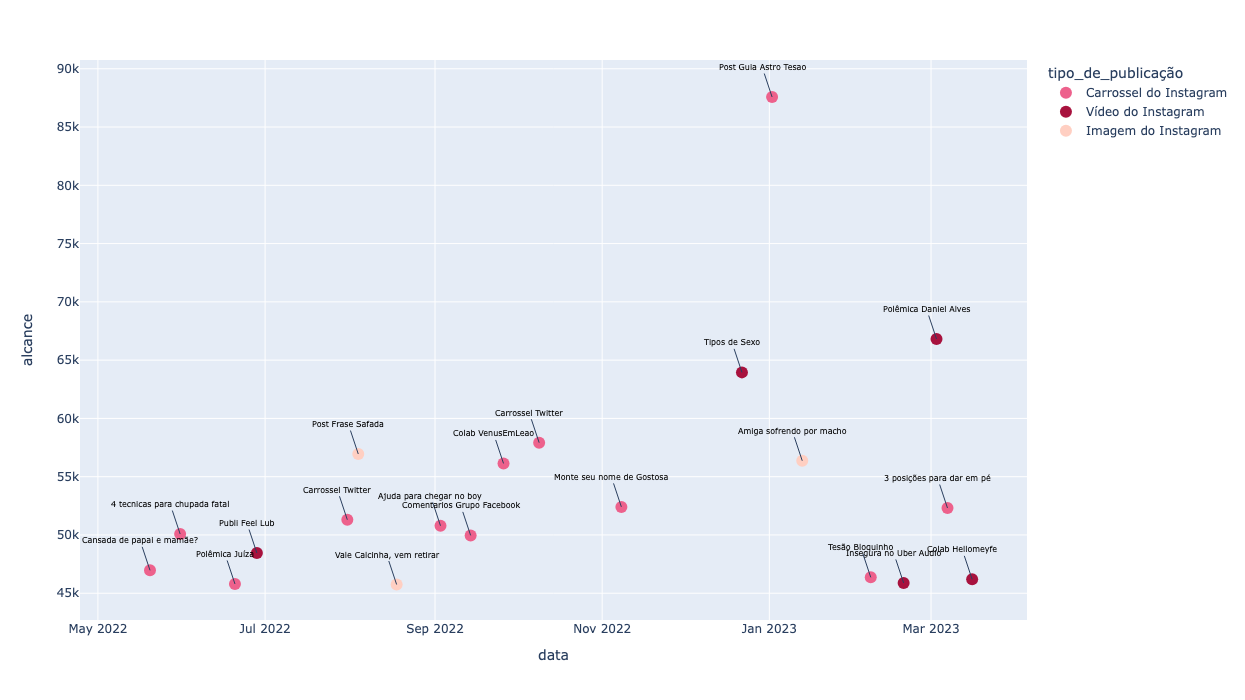

In [11]:

cores = ['#ED618C', '#A8123E', '#FFCFC2']


fig = px.scatter(df.sort_values('alcance', ascending=False).head(20),
                 x='data',
                 y='alcance',
                 width=1250,
                 height=700,
                 color='tipo_de_publicação',
                 color_discrete_sequence=cores)




fig.update_traces(mode='markers', marker=dict(size=12))


textos = ['Post Guia Astro Tesao', 'Polêmica Daniel Alves', 'Tipos de Sexo', 'Carrossel Twitter', 'Post Frase Safada',
          'Amiga sofrendo por macho', 'Colab VenusEmLeao', 'Monte seu nome de Gostosa', '3 posições para dar em pé',
          'Carrossel Twitter', 'Ajuda para chegar no boy', '4 tecnicas para chupada fatal', 'Comentarios Grupo Facebook',
          'Publi Feel Lub', 'Cansada de papai e mamãe?', 'Tesão Bloquinho', 'Colab Hellomeyfe', 'Insegura no Uber Audio',
          'Polêmica Juíza', 'Vale Calcinha, vem retirar']


adicionar_anotacoes(fig, df, 'data', 'alcance', textos)

fig.show()


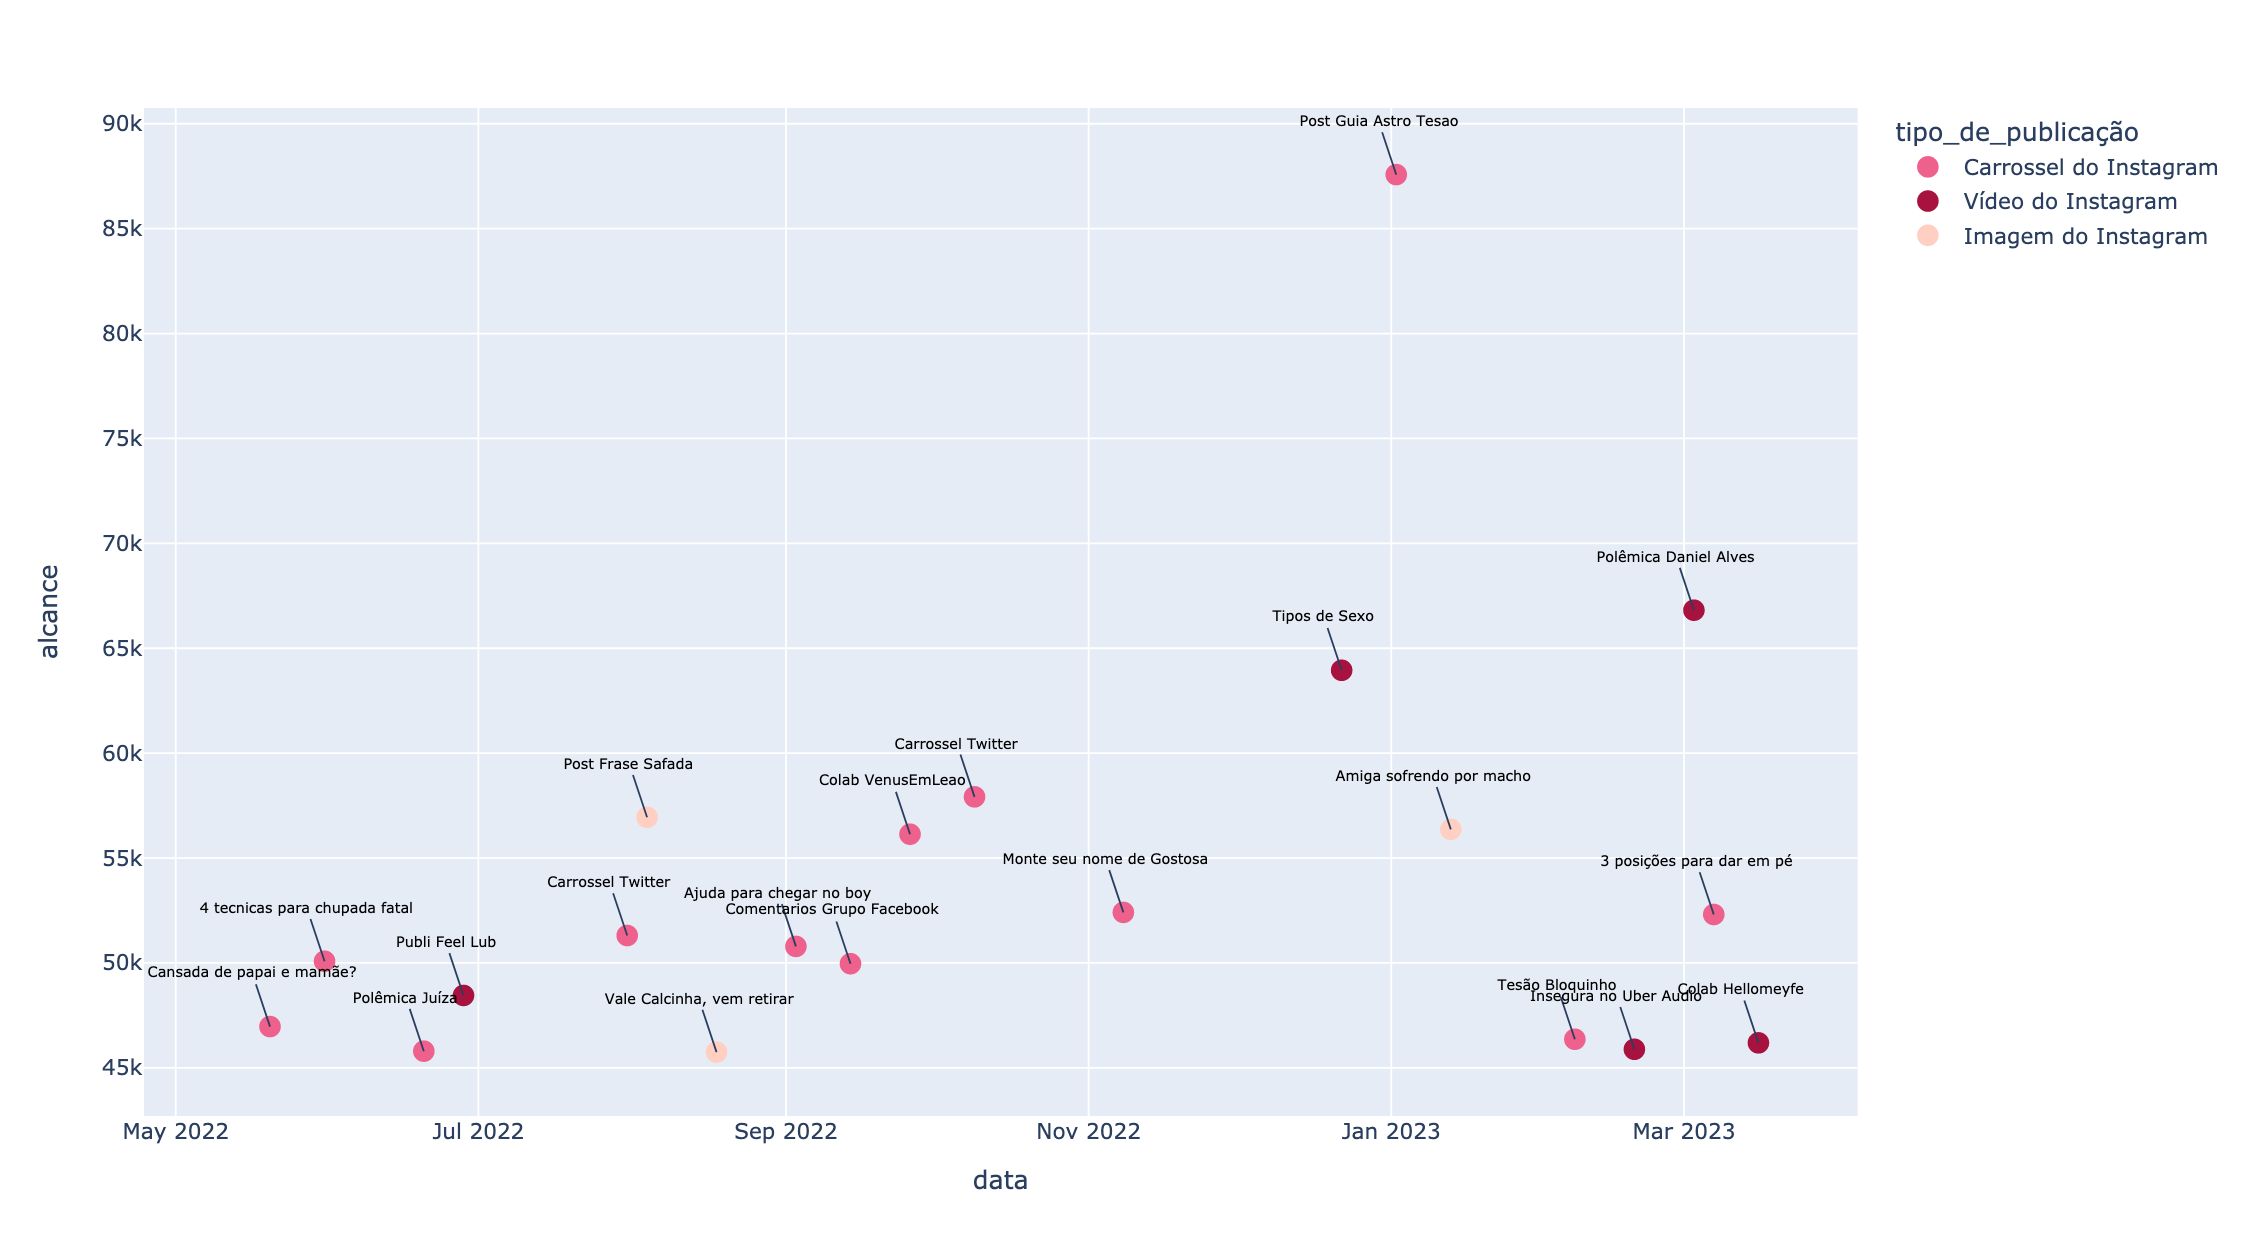

In [12]:
fig.show('png', scale=1.8)

## Dispersão Métrica Curtidas 

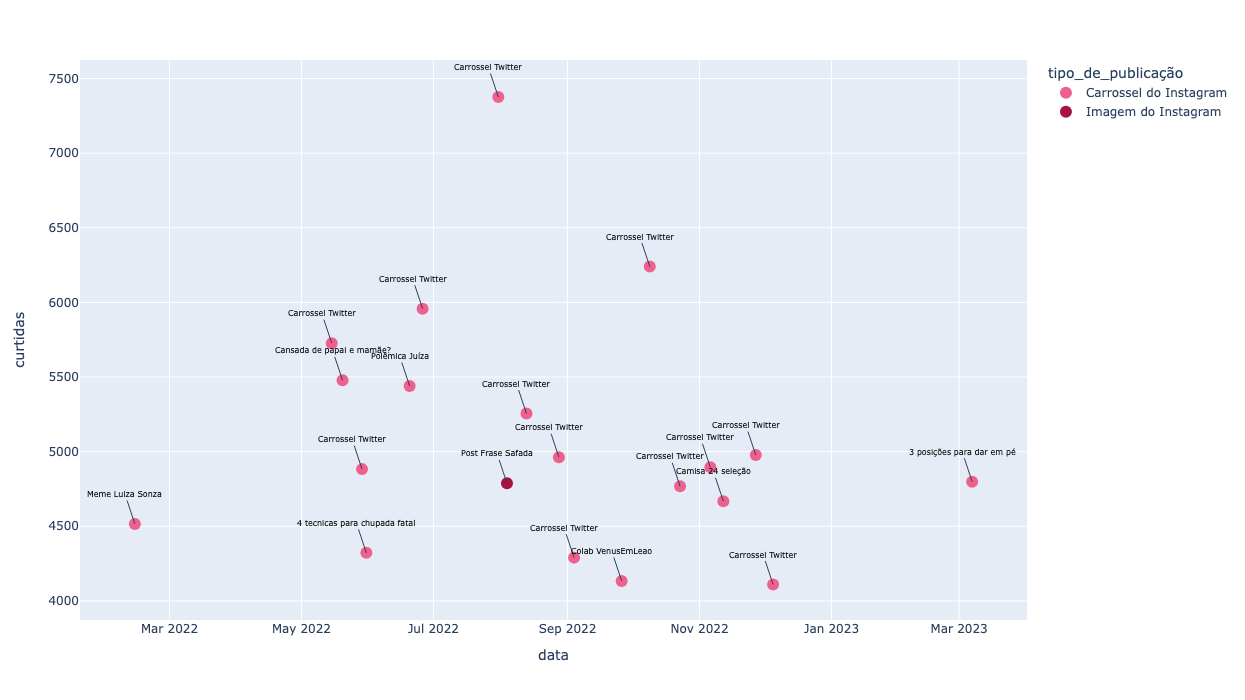

In [13]:

cores = ['#ED618C', '#A8123E', '#FFCFC2']

# Criar o gráfico de dispersão com as cores definidas
fig = px.scatter(df.sort_values('curtidas', ascending=False).head(20),
                 x='data',
                 y='curtidas',
                 width=1250,
                 height=700,
                 color='tipo_de_publicação',
                 color_discrete_sequence=cores)

fig.update_traces(mode='markers', marker=dict(size=12))

# Definir a lista de textos para as anotações
textos = ['Carrossel Twitter','Carrossel Twitter', 'Carrossel Twitter', 'Carrossel Twitter', 'Cansada de papai e mamãe?','Polêmica Juíza', 
          'Carrossel Twitter', 'Carrossel Twitter', 'Carrossel Twitter', 'Carrossel Twitter','Carrossel Twitter', '3 posições para dar em pé',
          'Post Frase Safada', 'Carrossel Twitter', 'Camisa 24 seleção', 'Meme Luiza Sonza', '4 tecnicas para chupada fatal','Carrossel Twitter',
          'Colab VenusEmLeao', 'Carrossel Twitter']

# Chamar a função para adicionar as anotações
adicionar_anotacoes(fig, df, 'data', 'curtidas', textos)

# Exibir o gráfico
fig.show()


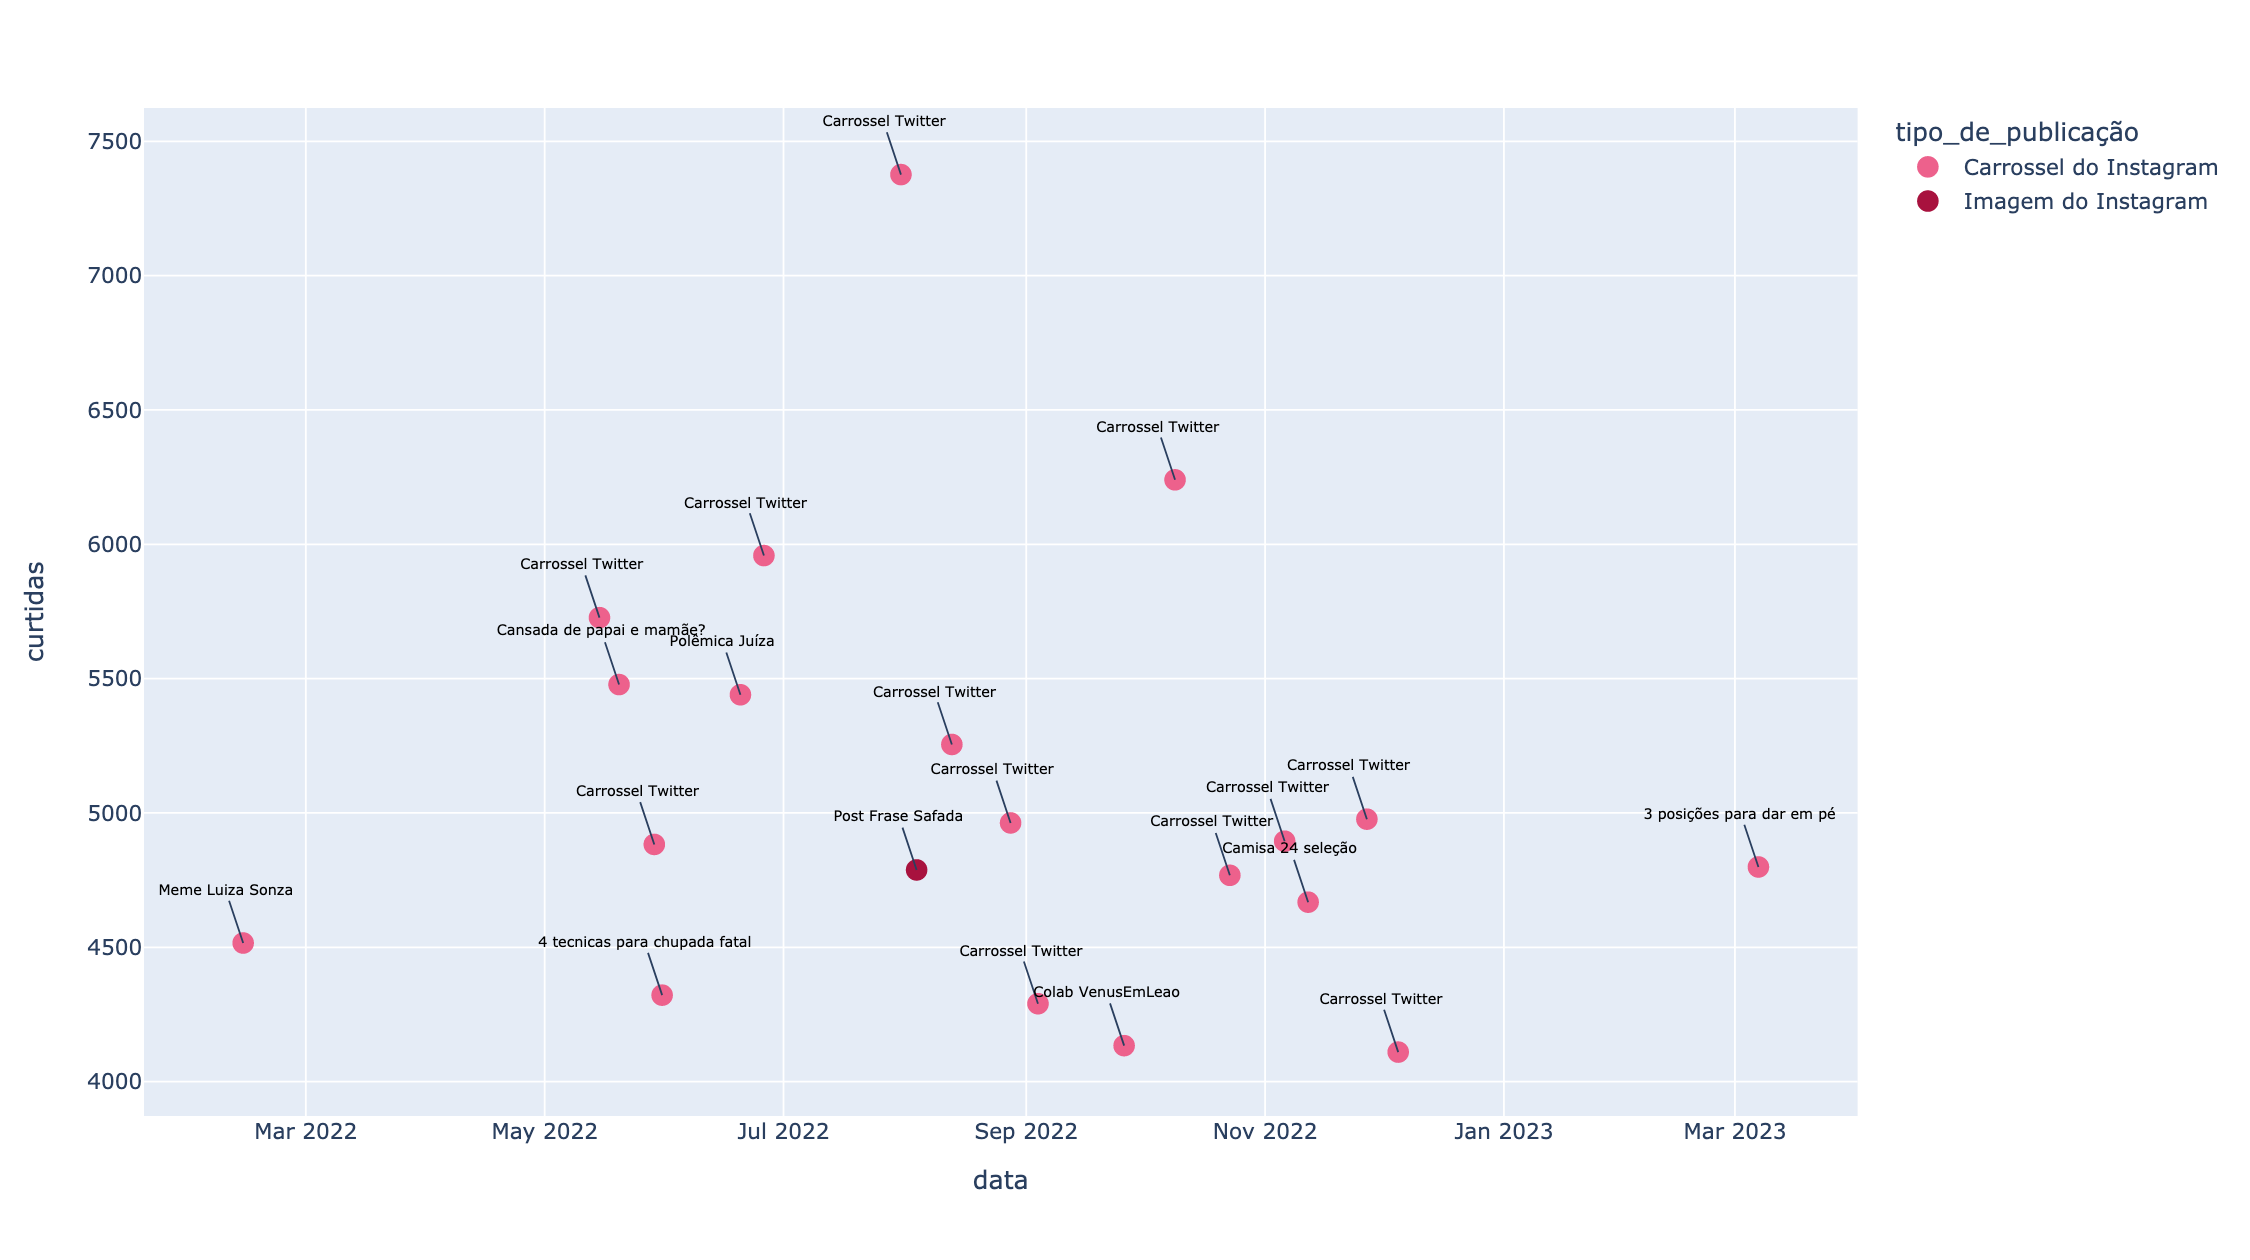

In [14]:
fig.show('png', scale=1.8)

## Dispersão Métrica Compartilhamentos

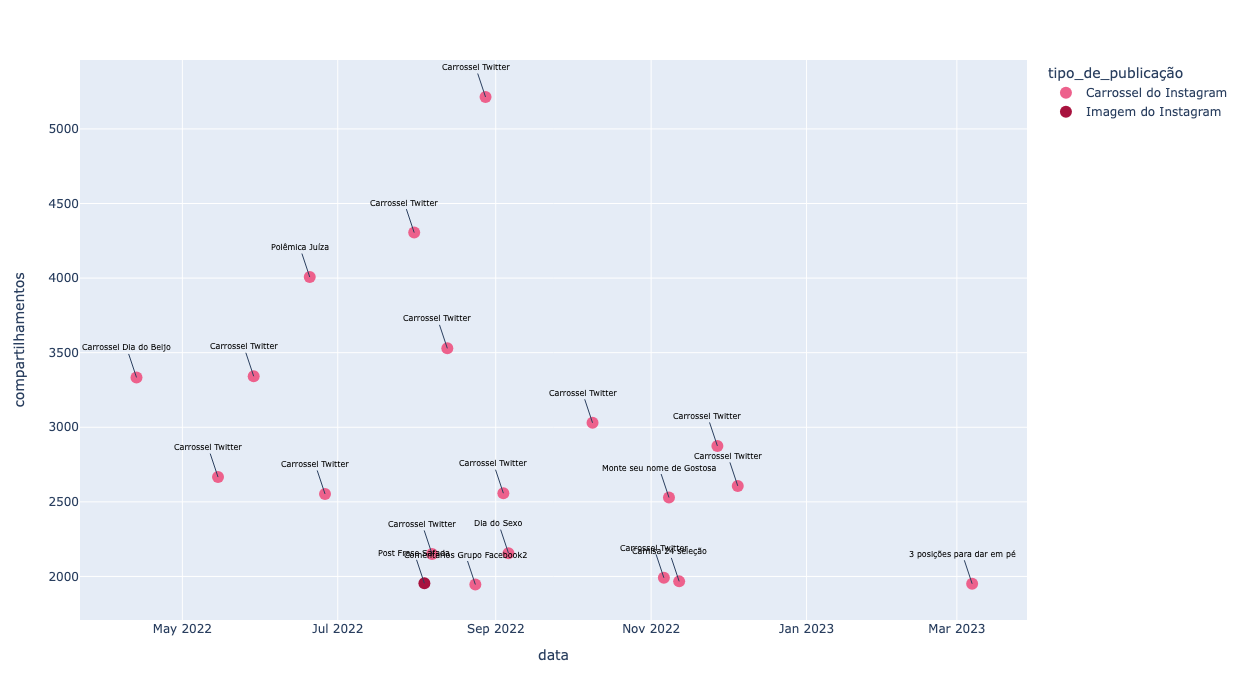

In [15]:

cores = ['#ED618C', '#A8123E', '#FFCFC2']


fig = px.scatter(df.sort_values('compartilhamentos', ascending=False).head(20),
                 x='data',
                 y='compartilhamentos',
                 width=1250,
                 height=700,
                 color='tipo_de_publicação',
                 color_discrete_sequence=cores)

fig.update_traces(mode='markers', marker=dict(size=12))


textos = ['Carrossel Twitter','Carrossel Twitter', 'Polêmica Juíza', 'Carrossel Twitter', 'Carrossel Twitter', 'Carrossel Dia do Beijo', 
          'Carrossel Twitter', 'Carrossel Twitter', 'Carrossel Twitter', 'Carrossel Twitter', 'Carrossel Twitter','Carrossel Twitter', 
          'Monte seu nome de Gostosa', 'Dia do Sexo', 'Carrossel Twitter', 'Carrossel Twitter', 'Camisa 24 seleção','Post Frase Safada',
          '3 posições para dar em pé','Comentarios Grupo Facebook2']


adicionar_anotacoes(fig, df, 'data', 'compartilhamentos', textos)


fig.show()


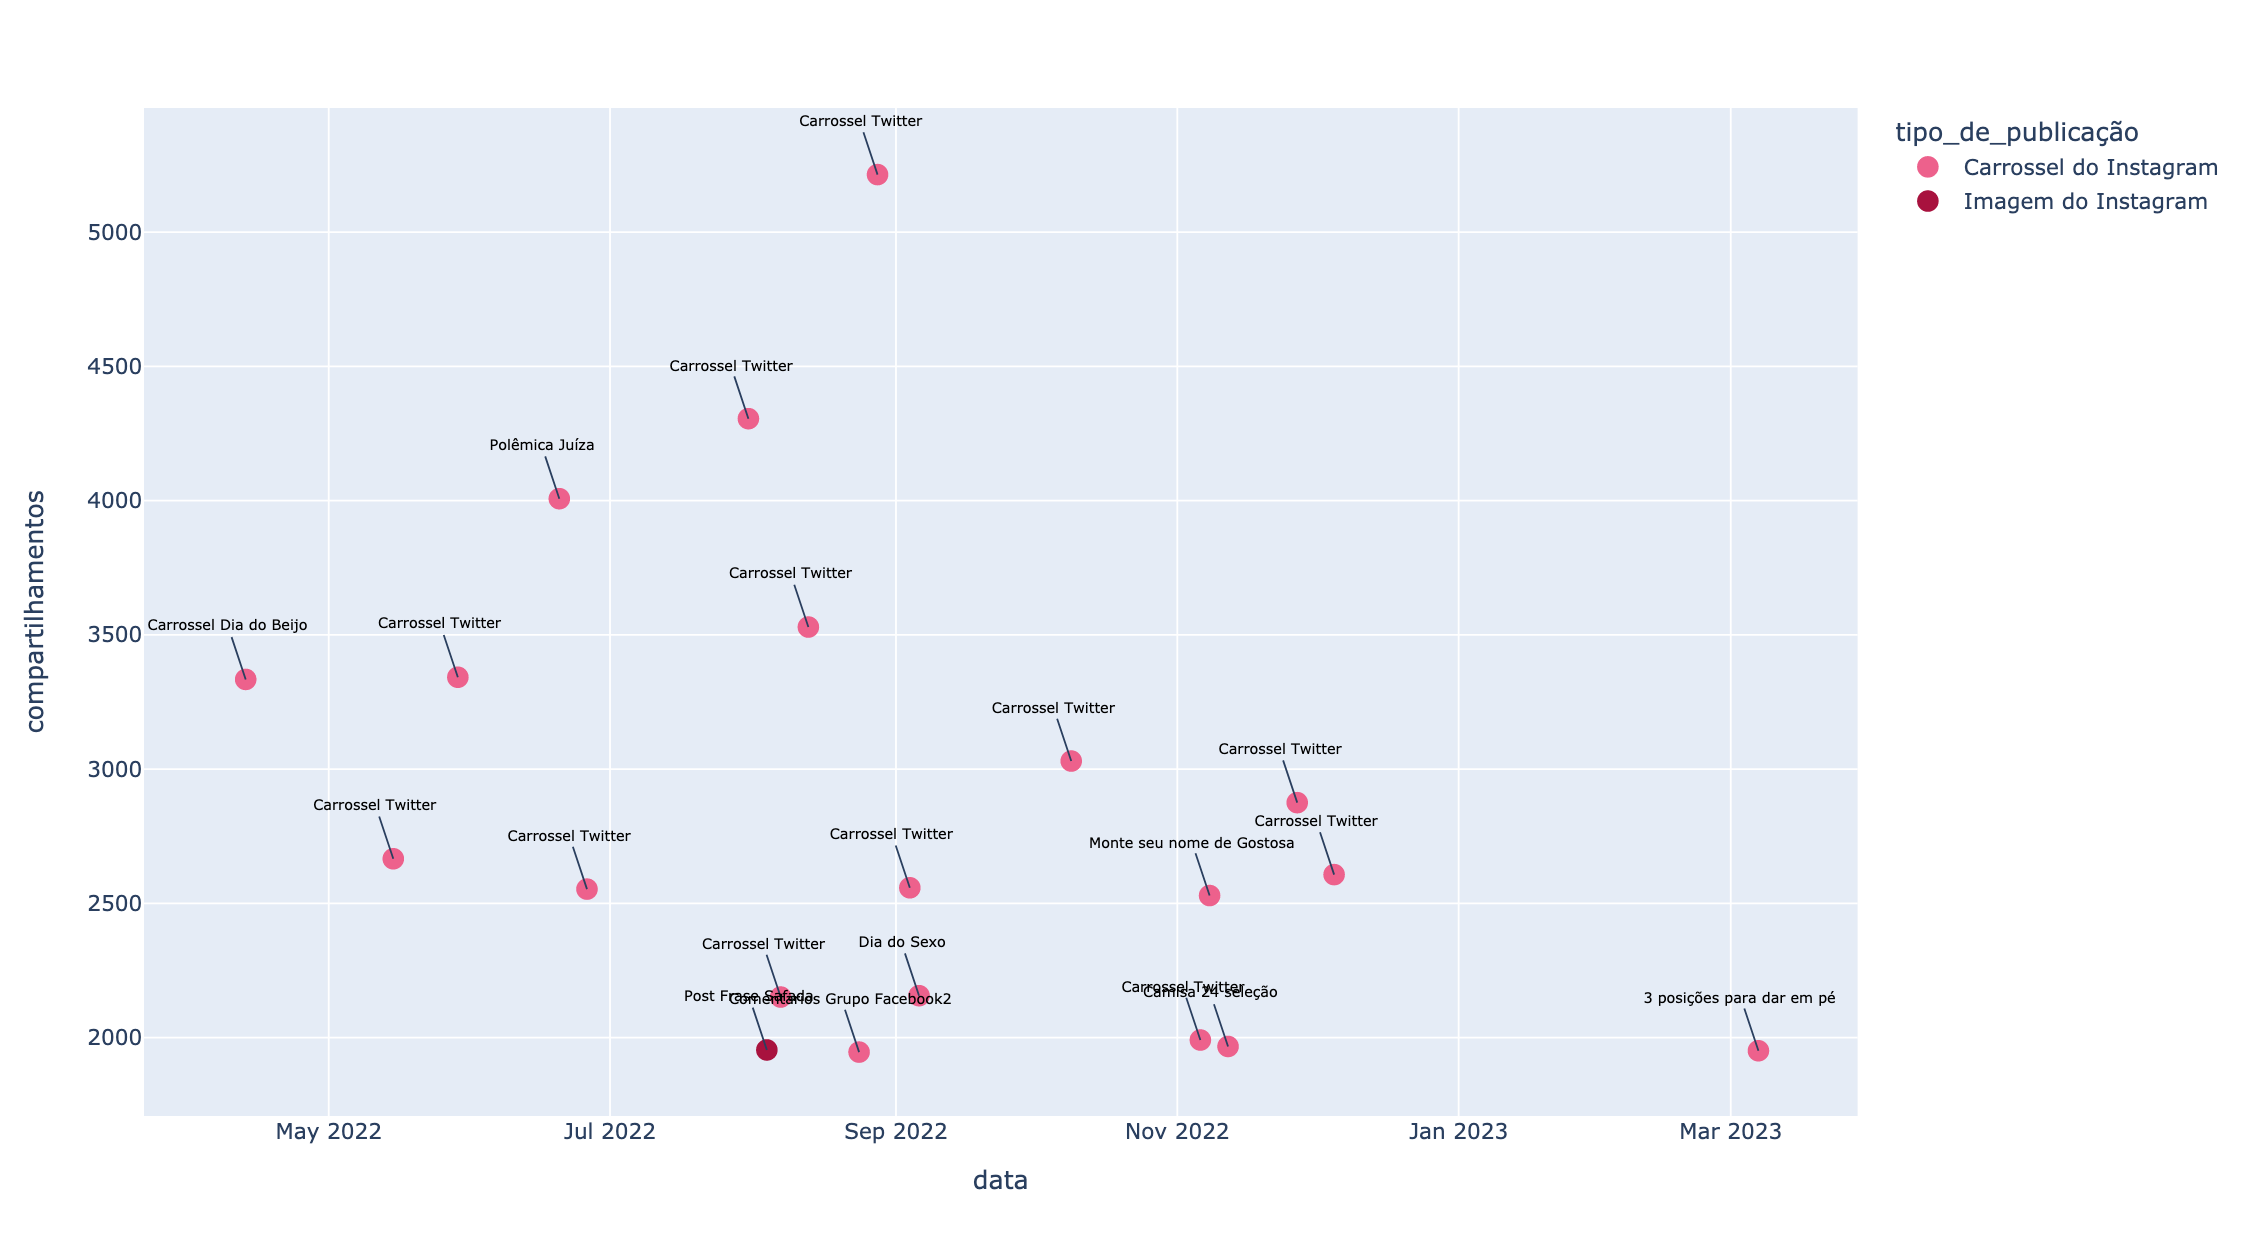

In [16]:
fig.show('png', scale=1.8)

## Dispersão Métrica Alcance por categoria de post 

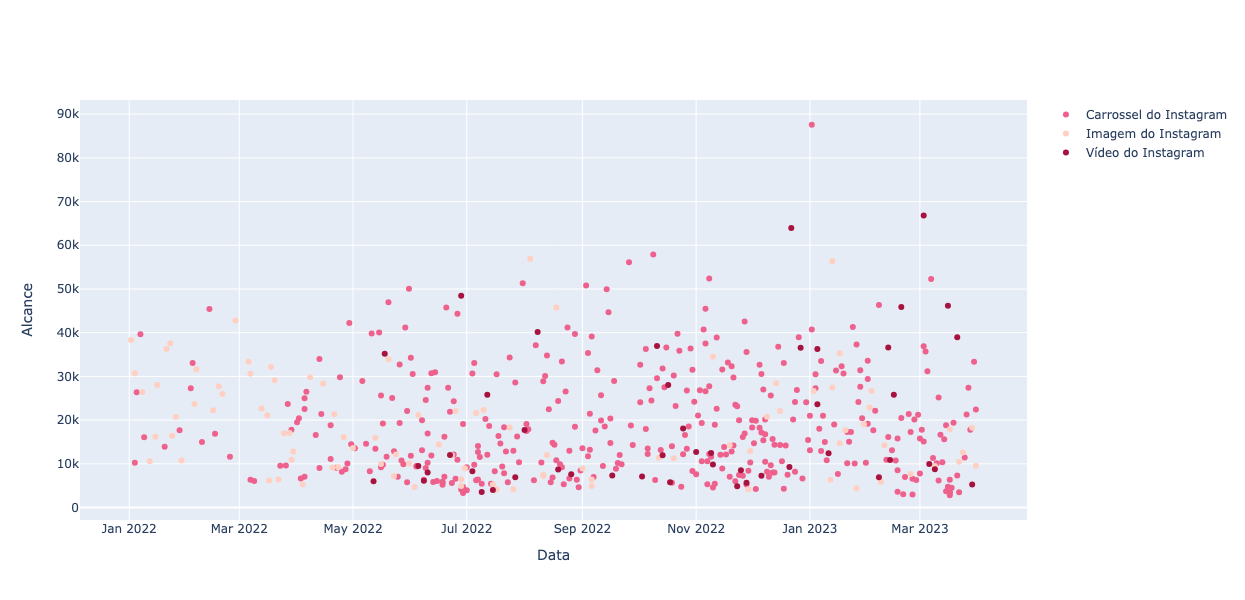

In [17]:
color_map = {
    'Carrossel do Instagram': '#ED618C',
    'Imagem do Instagram': '#FFCFC2',
    'Vídeo do Instagram': '#A8123E'
}

fig = go.Figure()

for category, color in color_map.items():
    filtered_data = df[df['tipo_de_publicação'] == category]
    fig.add_trace(go.Scatter(
        x=filtered_data['data'],
        y=filtered_data['alcance'],
        mode='markers',
        marker=dict(color=color),
        name=category
    ))

fig.update_layout(
    width=1000,
    height=600,
    xaxis_title='Data',
    yaxis_title='Alcance'
)

fig.show()

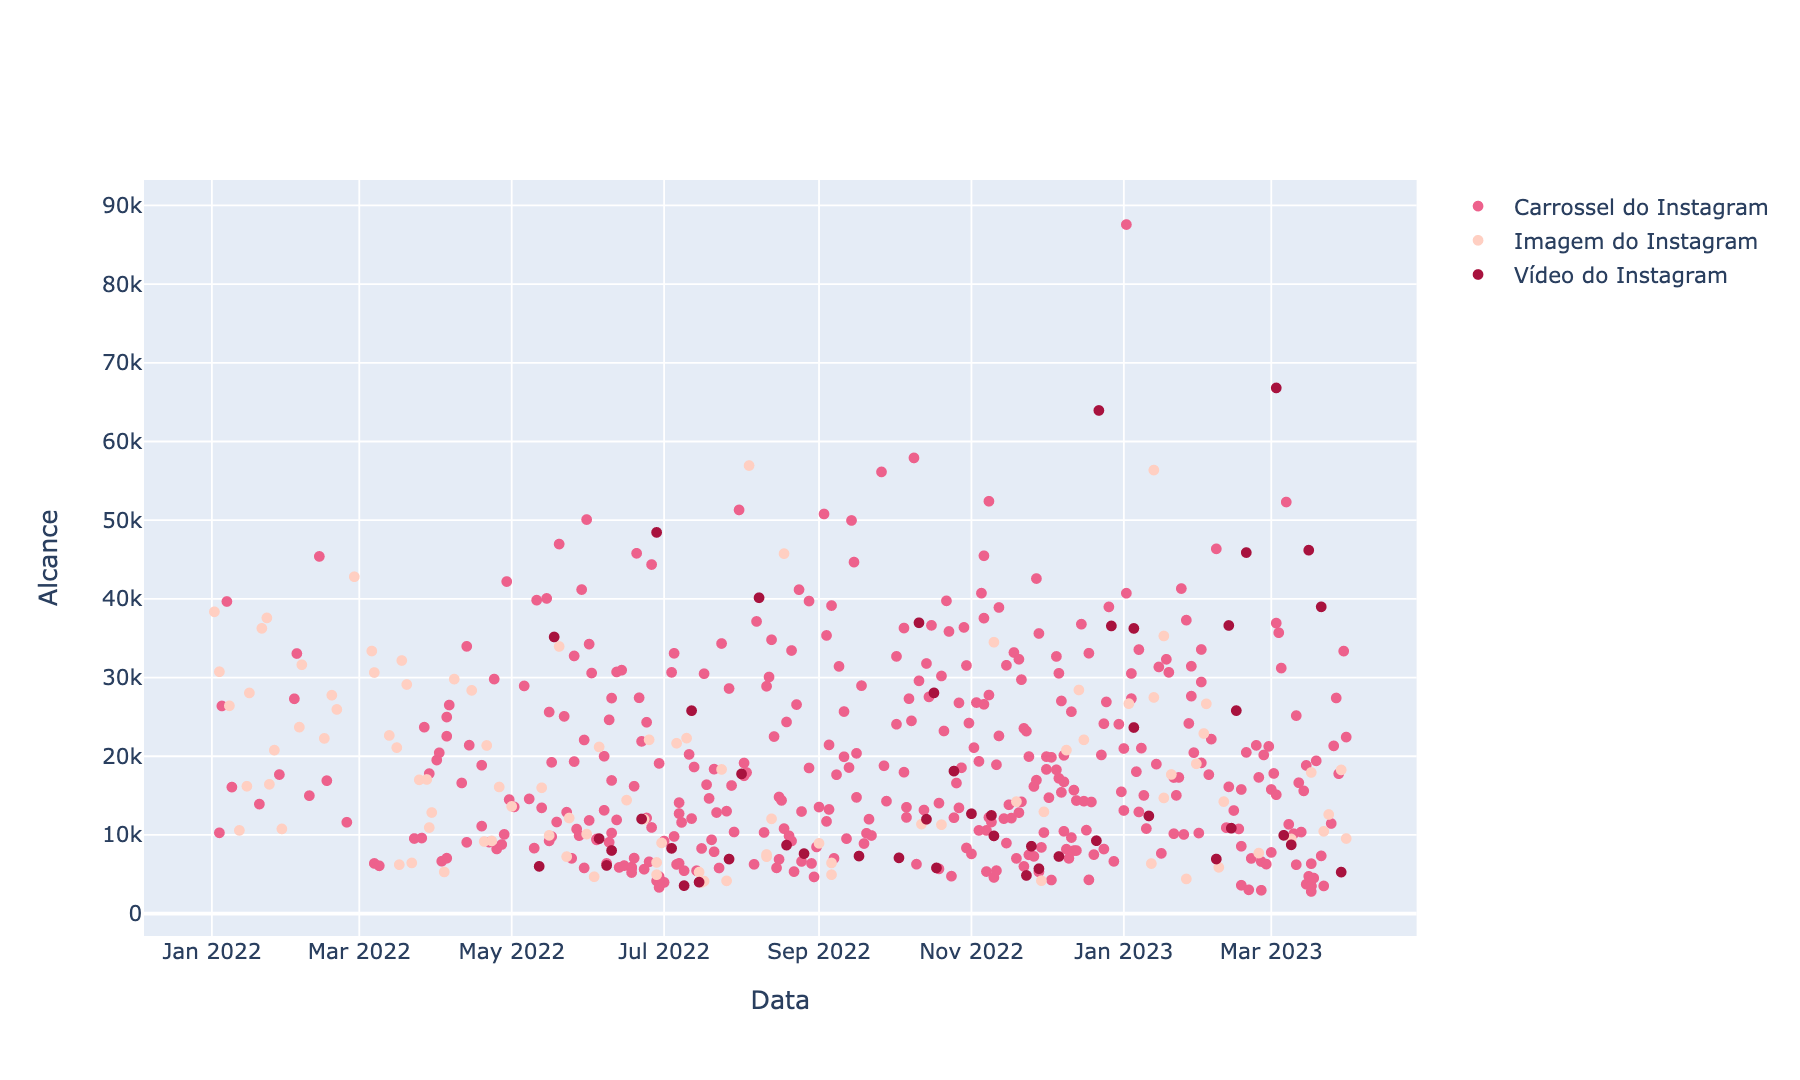

In [18]:
fig.show('png', scale=1.8)

# Dispersão Métrica Impressões por categoria de post 

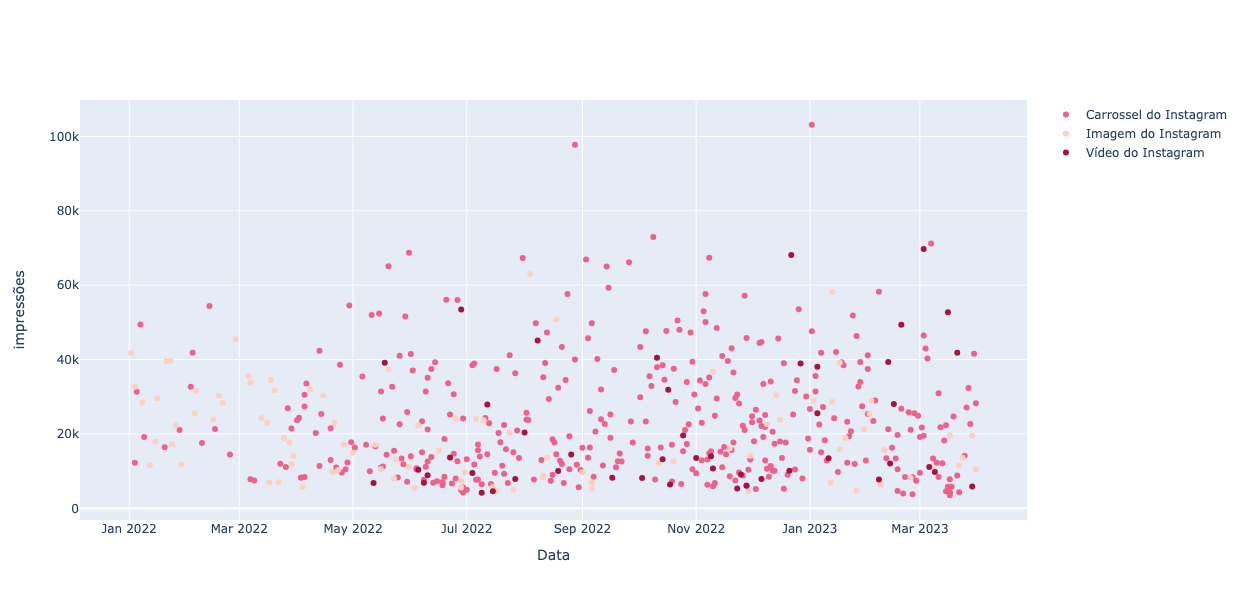

In [20]:
color_map = {
    'Carrossel do Instagram': '#ED618C',
    'Imagem do Instagram': '#FFCFC2',
    'Vídeo do Instagram': '#A8123E'
}

fig = go.Figure()

for category, color in color_map.items():
    filtered_data = df[df['tipo_de_publicação'] == category]
    fig.add_trace(go.Scatter(
        x=filtered_data['data'],
        y=filtered_data['impressões'],
        mode='markers',
        marker=dict(color=color),
        name=category
    ))

fig.update_layout(
    width=1000,
    height=600,
    xaxis_title='Data',
    yaxis_title='impressões'
)

fig.show()

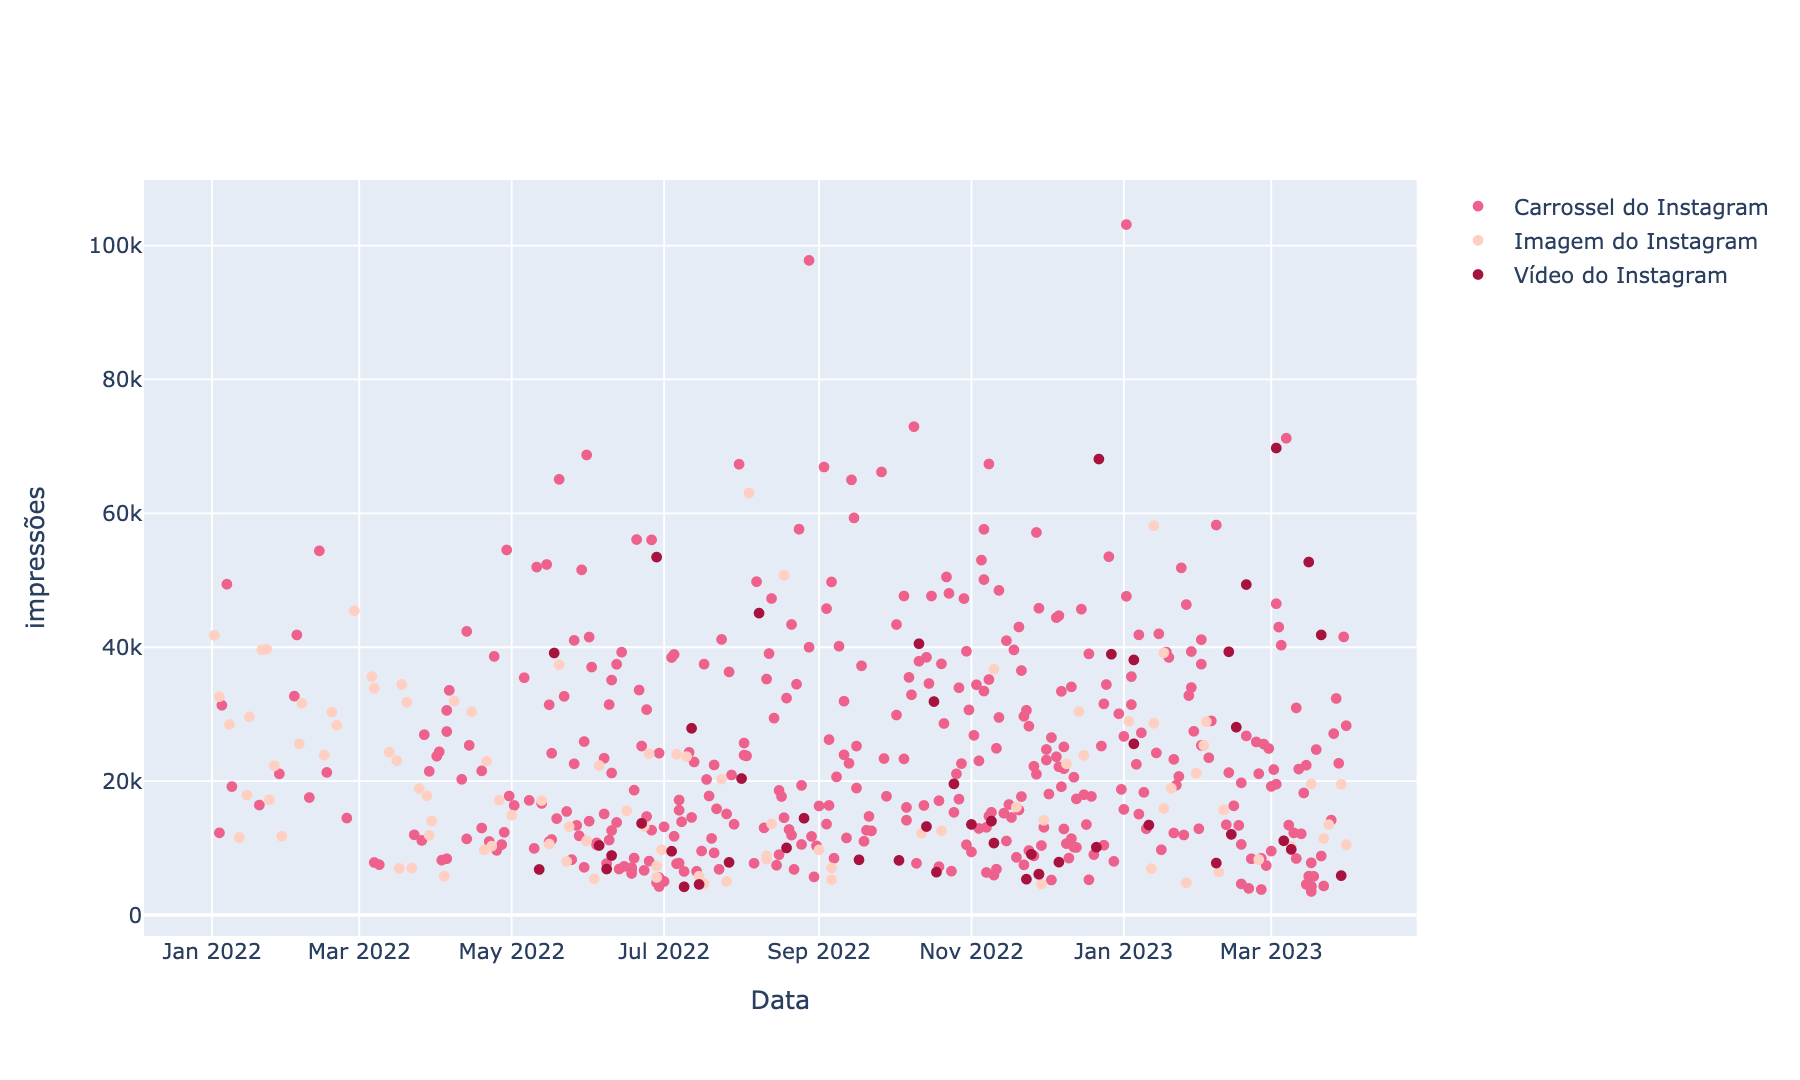

In [21]:
fig.show('png', scale=1.8)

## Dispersão Métrica curtidas

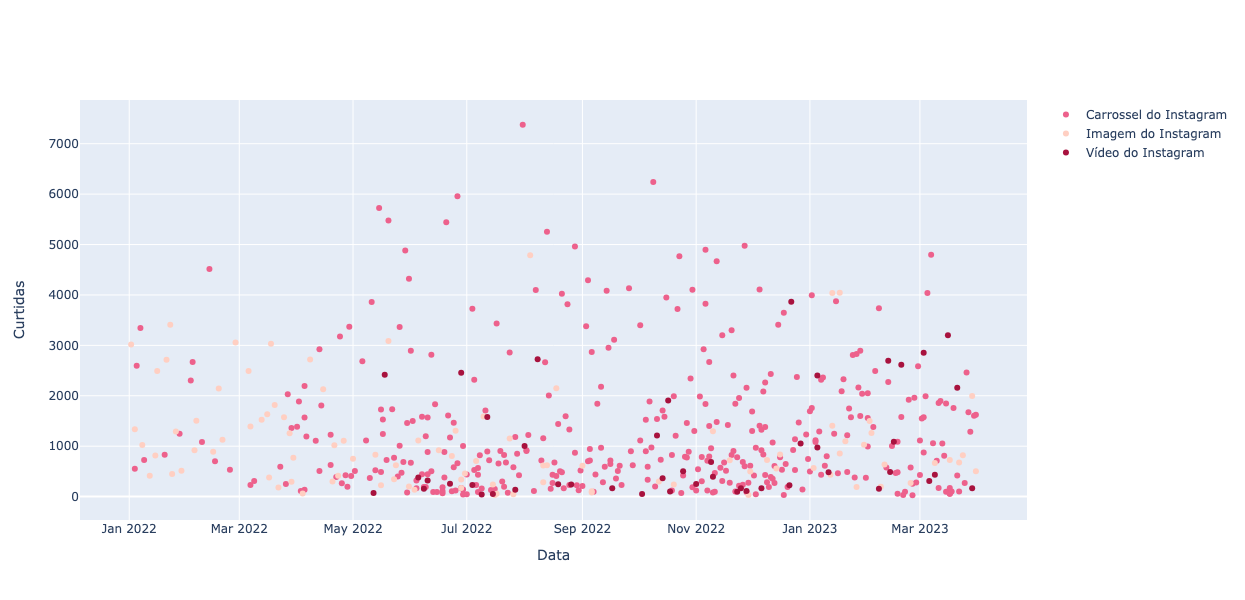

In [22]:
color_map = {
    'Carrossel do Instagram': '#ED618C',
    'Imagem do Instagram': '#FFCFC2',
    'Vídeo do Instagram': '#A8123E'
}

fig = go.Figure()

for category, color in color_map.items():
    filtered_data = df[df['tipo_de_publicação'] == category]
    fig.add_trace(go.Scatter(
        x=filtered_data['data'],
        y=filtered_data['curtidas'],
        mode='markers',
        marker=dict(color=color),
        name=category
    ))

fig.update_layout(
    width=1000,
    height=600,
    xaxis_title='Data',
    yaxis_title='Curtidas'
)

fig.show()

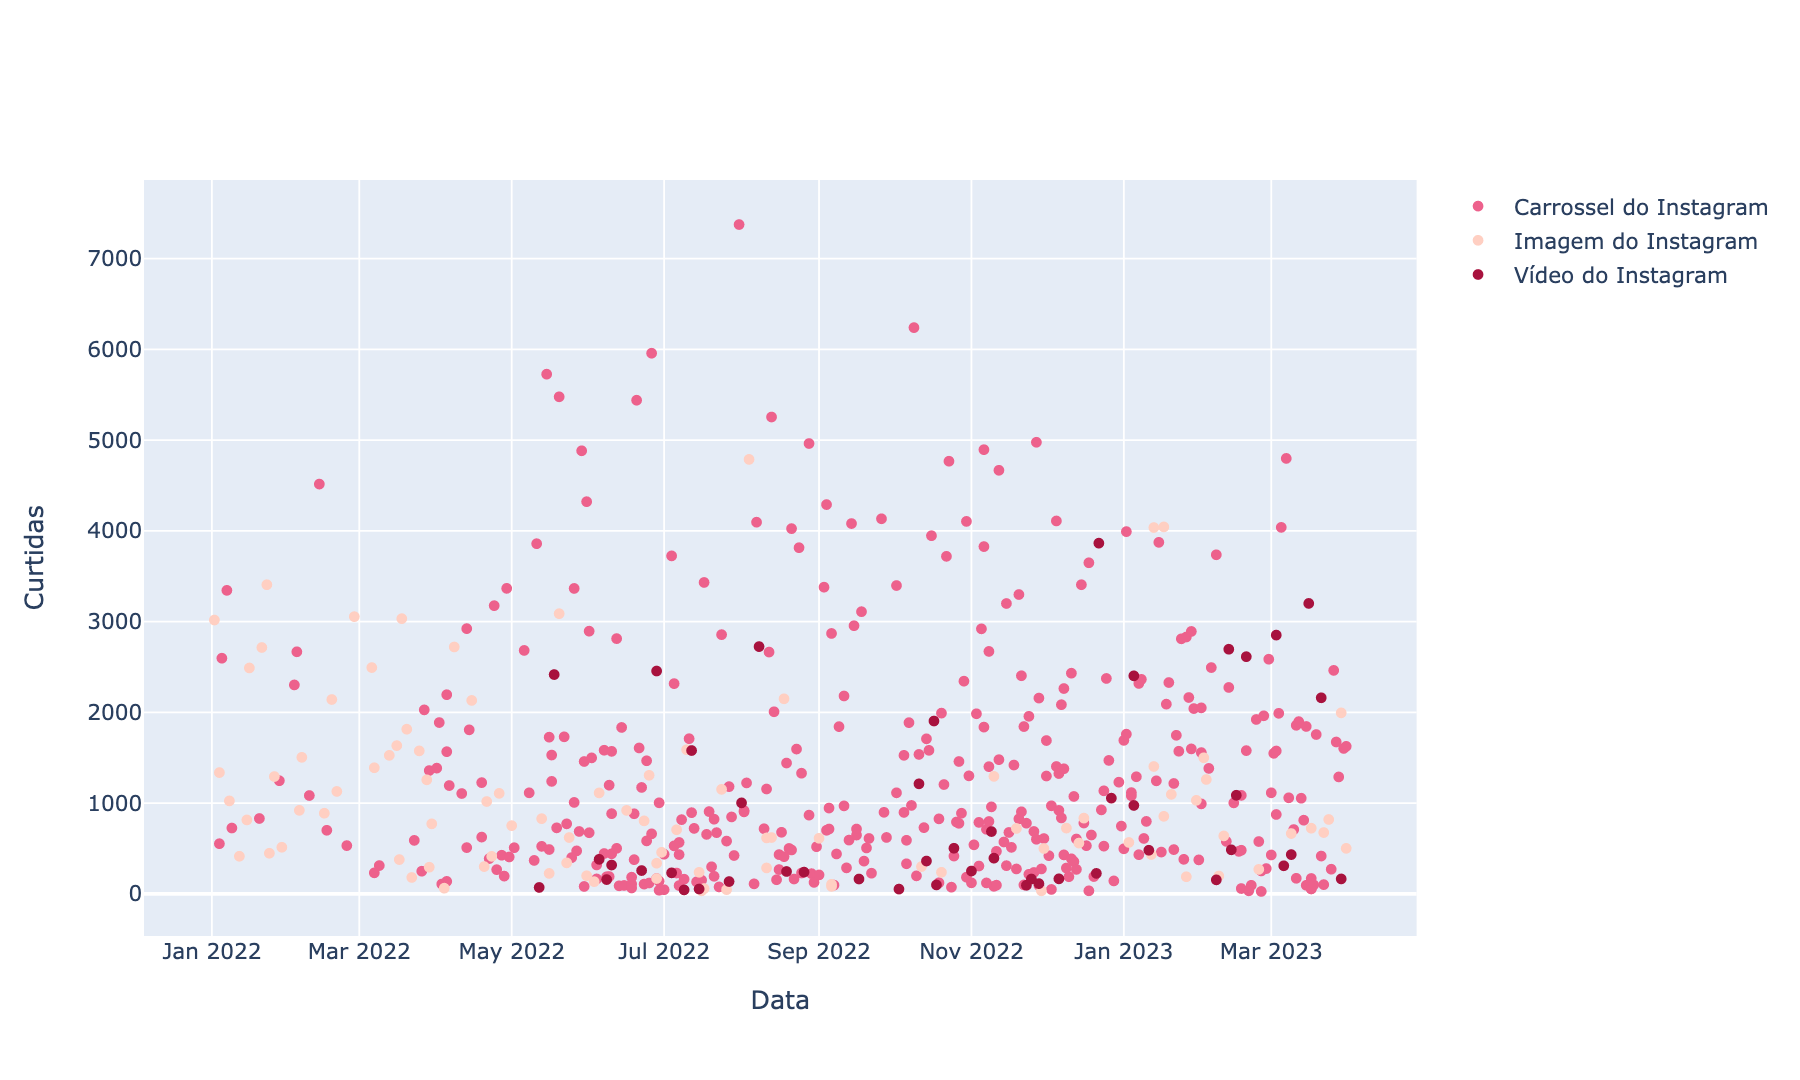

In [23]:
fig.show('png', scale=1.8)

## Média e Desvio padrão por Alcance

In [24]:
df_aux = df[['tipo_de_publicação', 'alcance']].groupby('tipo_de_publicação').agg({'alcance':['mean','std']}).round()

df_aux.columns = ['alcance médio', 'Desvio padrão']

df_aux = df_aux.reset_index()

df_aux

,tipo_de_publicação,alcance médio,Desvio padrão
0,Carrossel do Instagram,19201.0,12267.0
1,Imagem do Instagram,18484.0,11644.0
2,Vídeo do Instagram,19339.0,16646.0


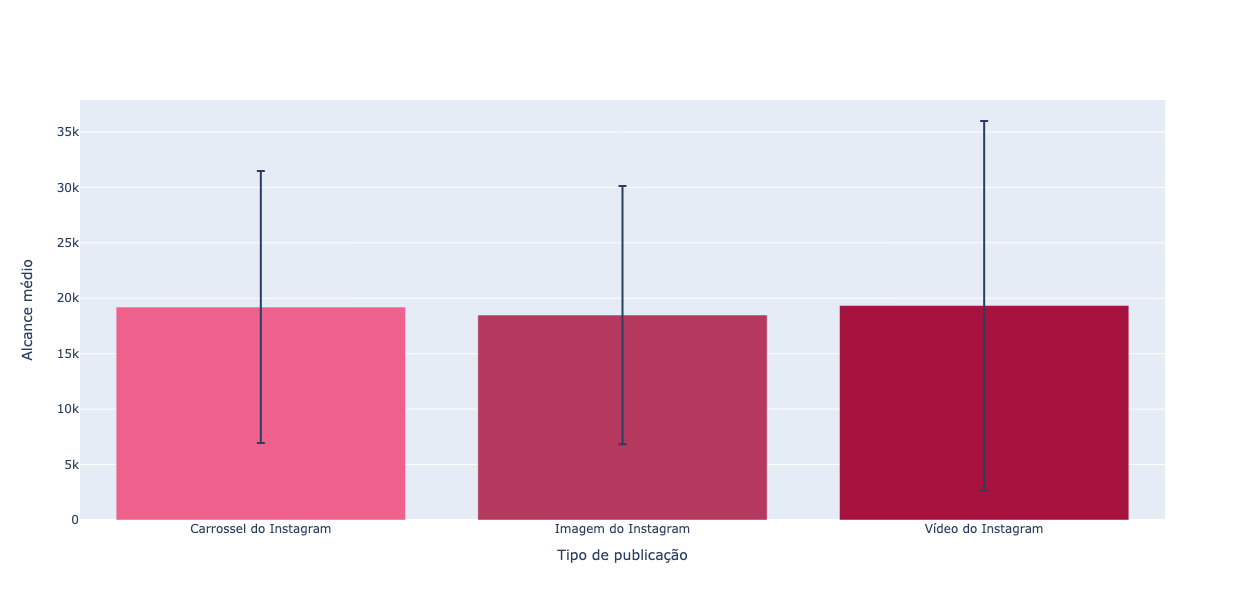

In [25]:
fig = go.Figure()

fig.add_trace(go.Bar(
    name='Control',
    x=df_aux['tipo_de_publicação'],
    y=df_aux['alcance médio'],
    error_y=dict(type='data', array=df_aux['Desvio padrão']),
    marker=dict(color=['#ED618C', '#B5385E','#A8123E'])  
))

fig.update_layout(
    barmode='group',
    width=1200,
    height=600,
    yaxis_title='Alcance médio',
    xaxis_title='Tipo de publicação'
)

fig.show()

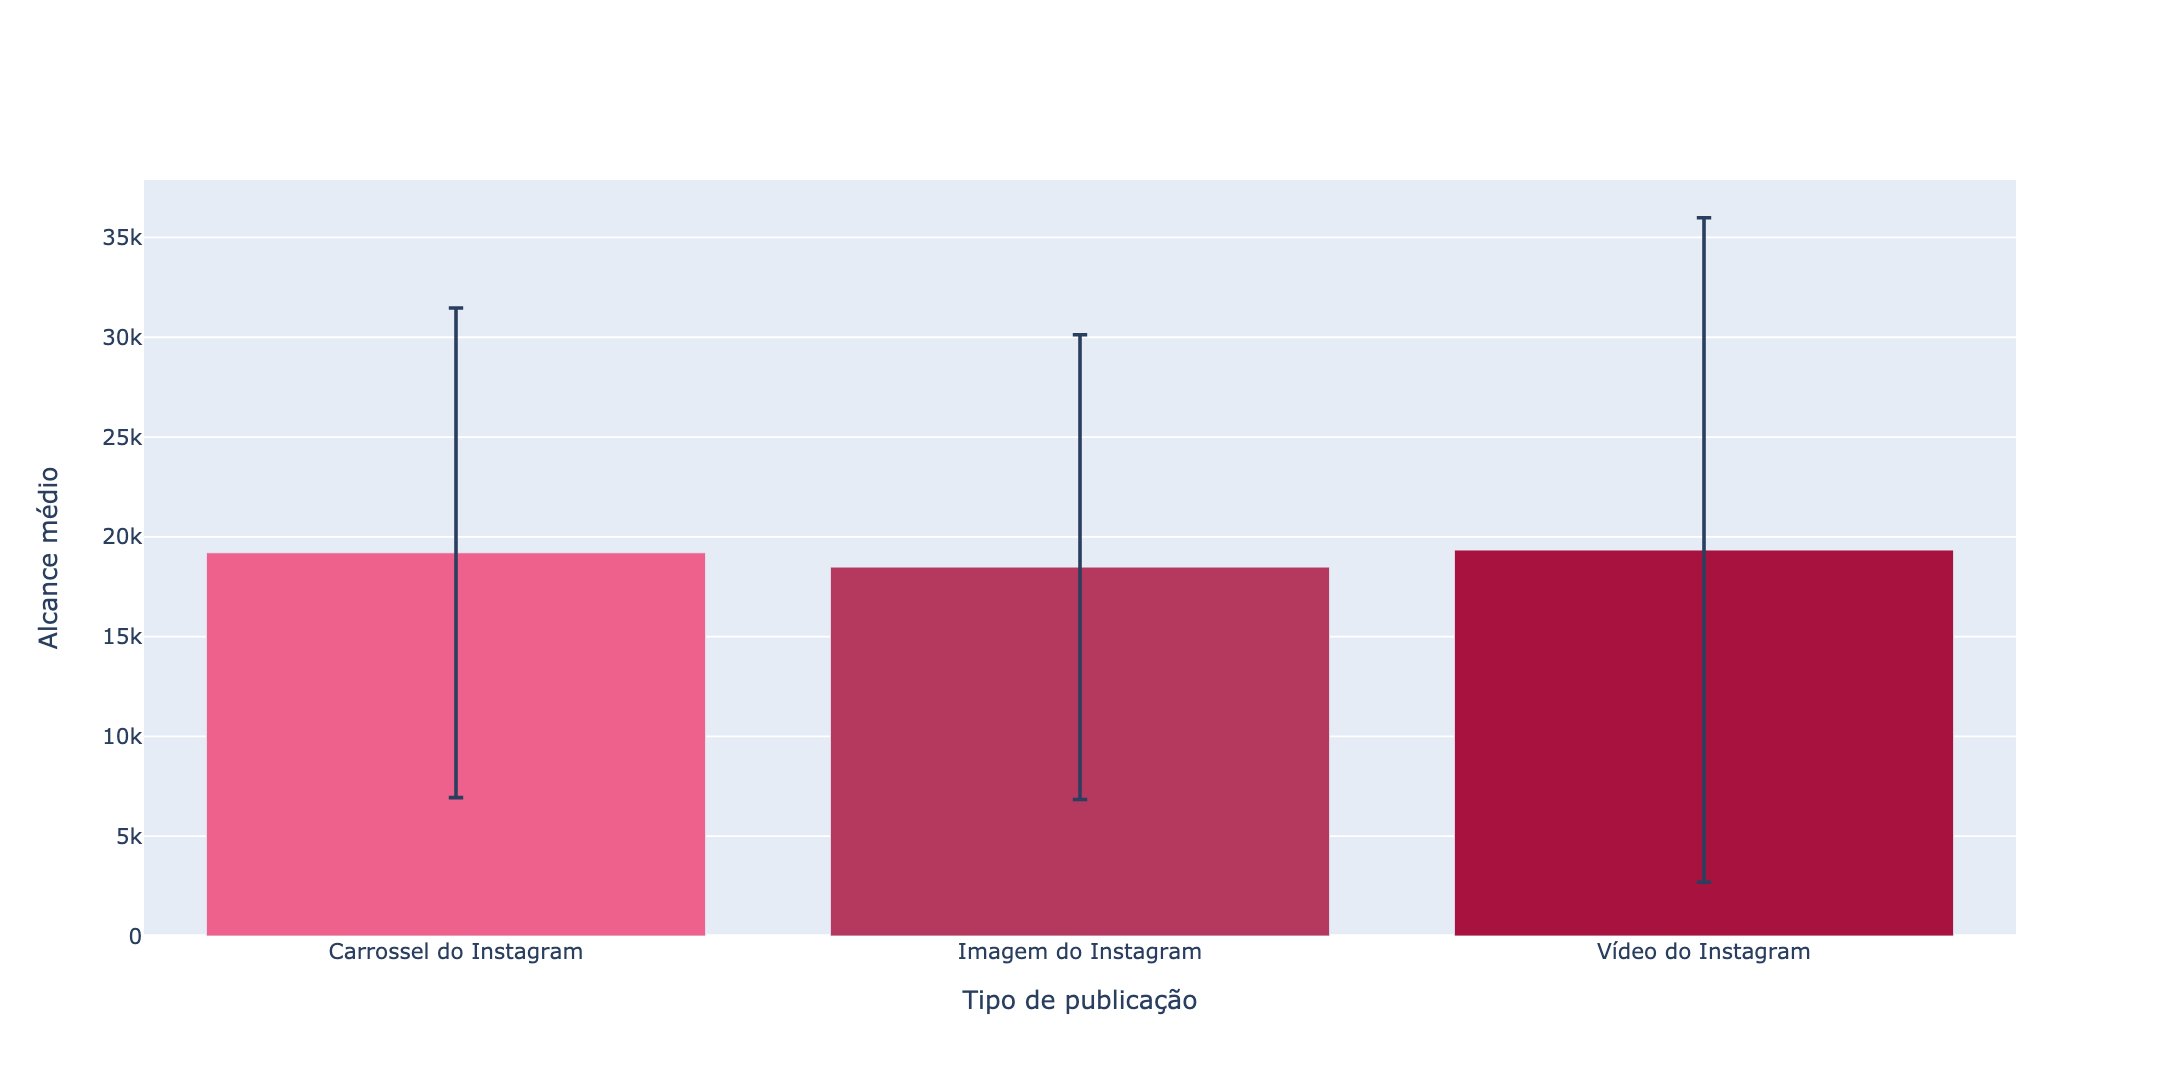

In [26]:
fig.show('png', scale=1.8)

# Média e Desvio Padrão por Curtidas 

In [27]:
df_aux2 = df[['tipo_de_publicação', 'curtidas']].groupby('tipo_de_publicação').agg({'curtidas':['mean','std']}).round()

df_aux2.columns = ['media de curtidas', 'Desvio padrão']

df_aux2 = df_aux2.reset_index()

df_aux2

,tipo_de_publicação,media de curtidas,Desvio padrão
0,Carrossel do Instagram,1355.0,1323.0
1,Imagem do Instagram,1092.0,997.0
2,Vídeo do Instagram,929.0,1053.0


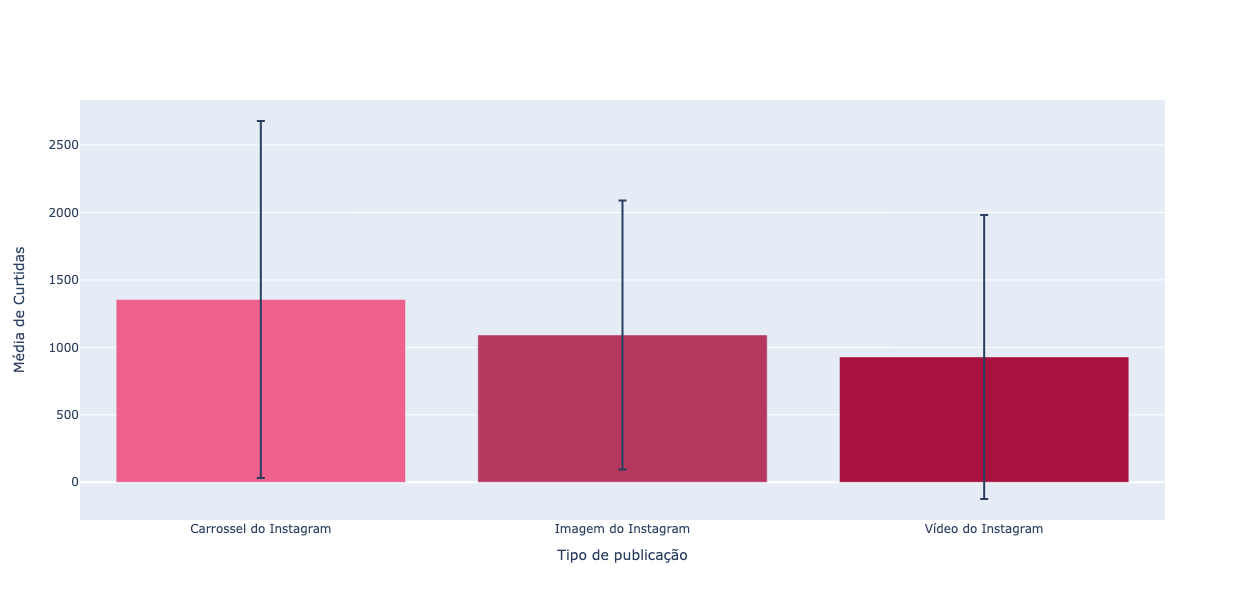

In [28]:
fig = go.Figure()

fig.add_trace(go.Bar(
    name='Control',
    x=df_aux2['tipo_de_publicação'],
    y=df_aux2['media de curtidas'],
    error_y=dict(type='data', array=df_aux2['Desvio padrão']),
    marker=dict(color=['#ED618C', '#B5385E','#A8123E'])  
))

fig.update_layout(
    barmode='group',
    width=1200,
    height=600,
    yaxis_title='Média de Curtidas',
    xaxis_title='Tipo de publicação'
)

fig.show()

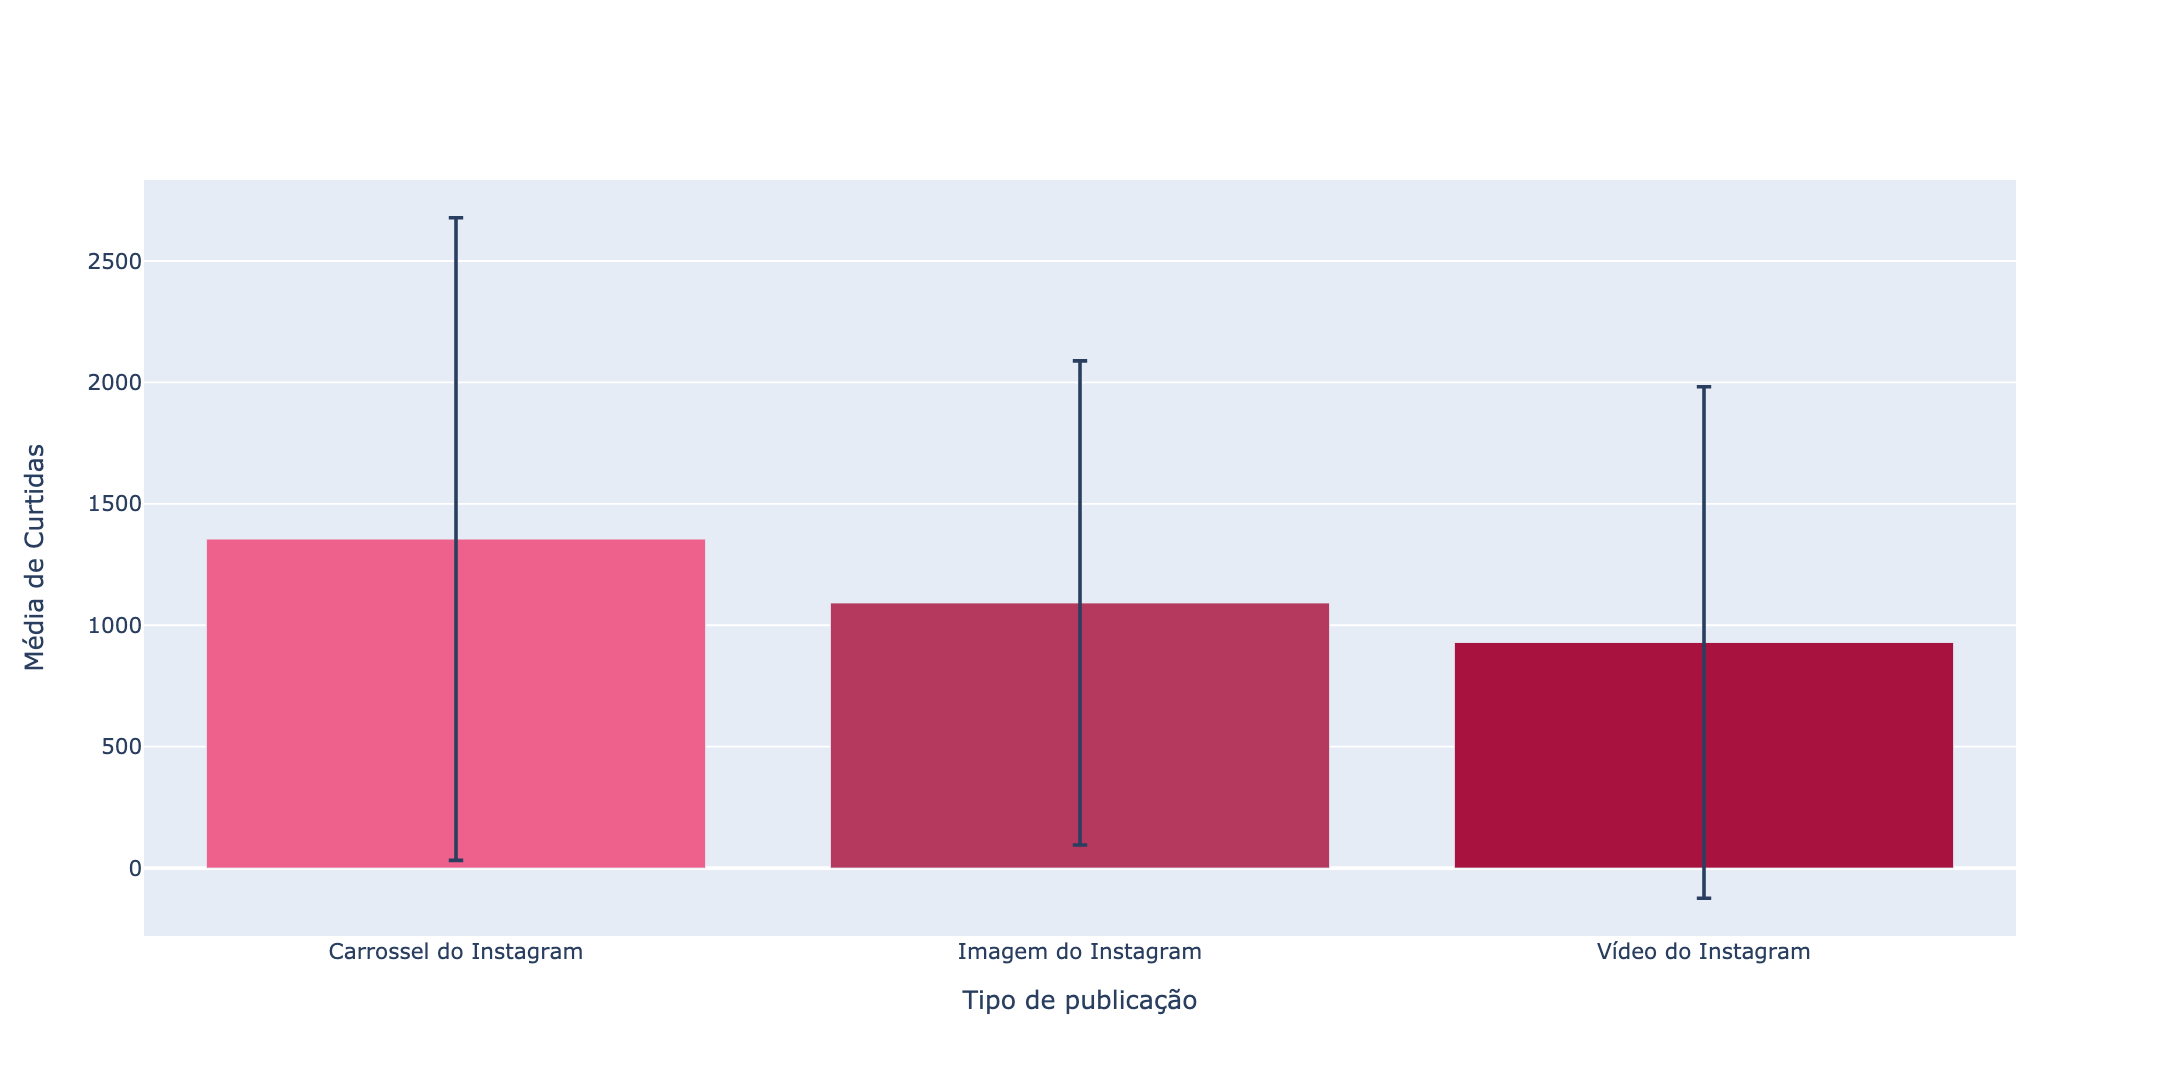

In [29]:
fig.show('png', scale=1.8)

# Média e Desvio Padrão por Compartilhamento 

In [30]:
df_aux3 = df[['tipo_de_publicação', 'compartilhamentos']].groupby('tipo_de_publicação').agg({'compartilhamentos':['mean','std']}).round()

df_aux3.columns = ['media de compartilhamento', 'Desvio padrão']

df_aux3 = df_aux3.reset_index()

df_aux3


,tipo_de_publicação,media de compartilhamento,Desvio padrão
0,Carrossel do Instagram,423.0,713.0
1,Imagem do Instagram,227.0,352.0
2,Vídeo do Instagram,210.0,353.0


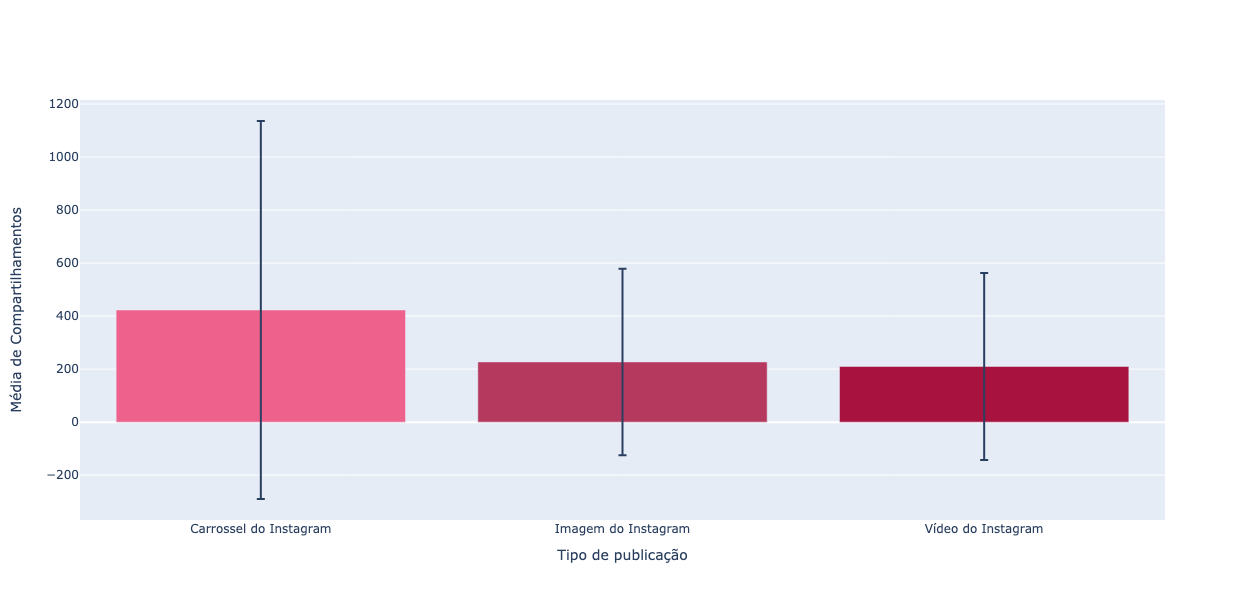

In [31]:
fig = go.Figure()

fig.add_trace(go.Bar(
    name='Control',
    x=df_aux3['tipo_de_publicação'],
    y=df_aux3['media de compartilhamento'],
    error_y=dict(type='data', array=df_aux3['Desvio padrão']),
    marker=dict(color=['#ED618C', '#B5385E','#A8123E'])  
))

fig.update_layout(
    barmode='group',
    width=1200,
    height=600,
    yaxis_title='Média de Compartilhamentos',
    xaxis_title='Tipo de publicação'
)

fig.show()

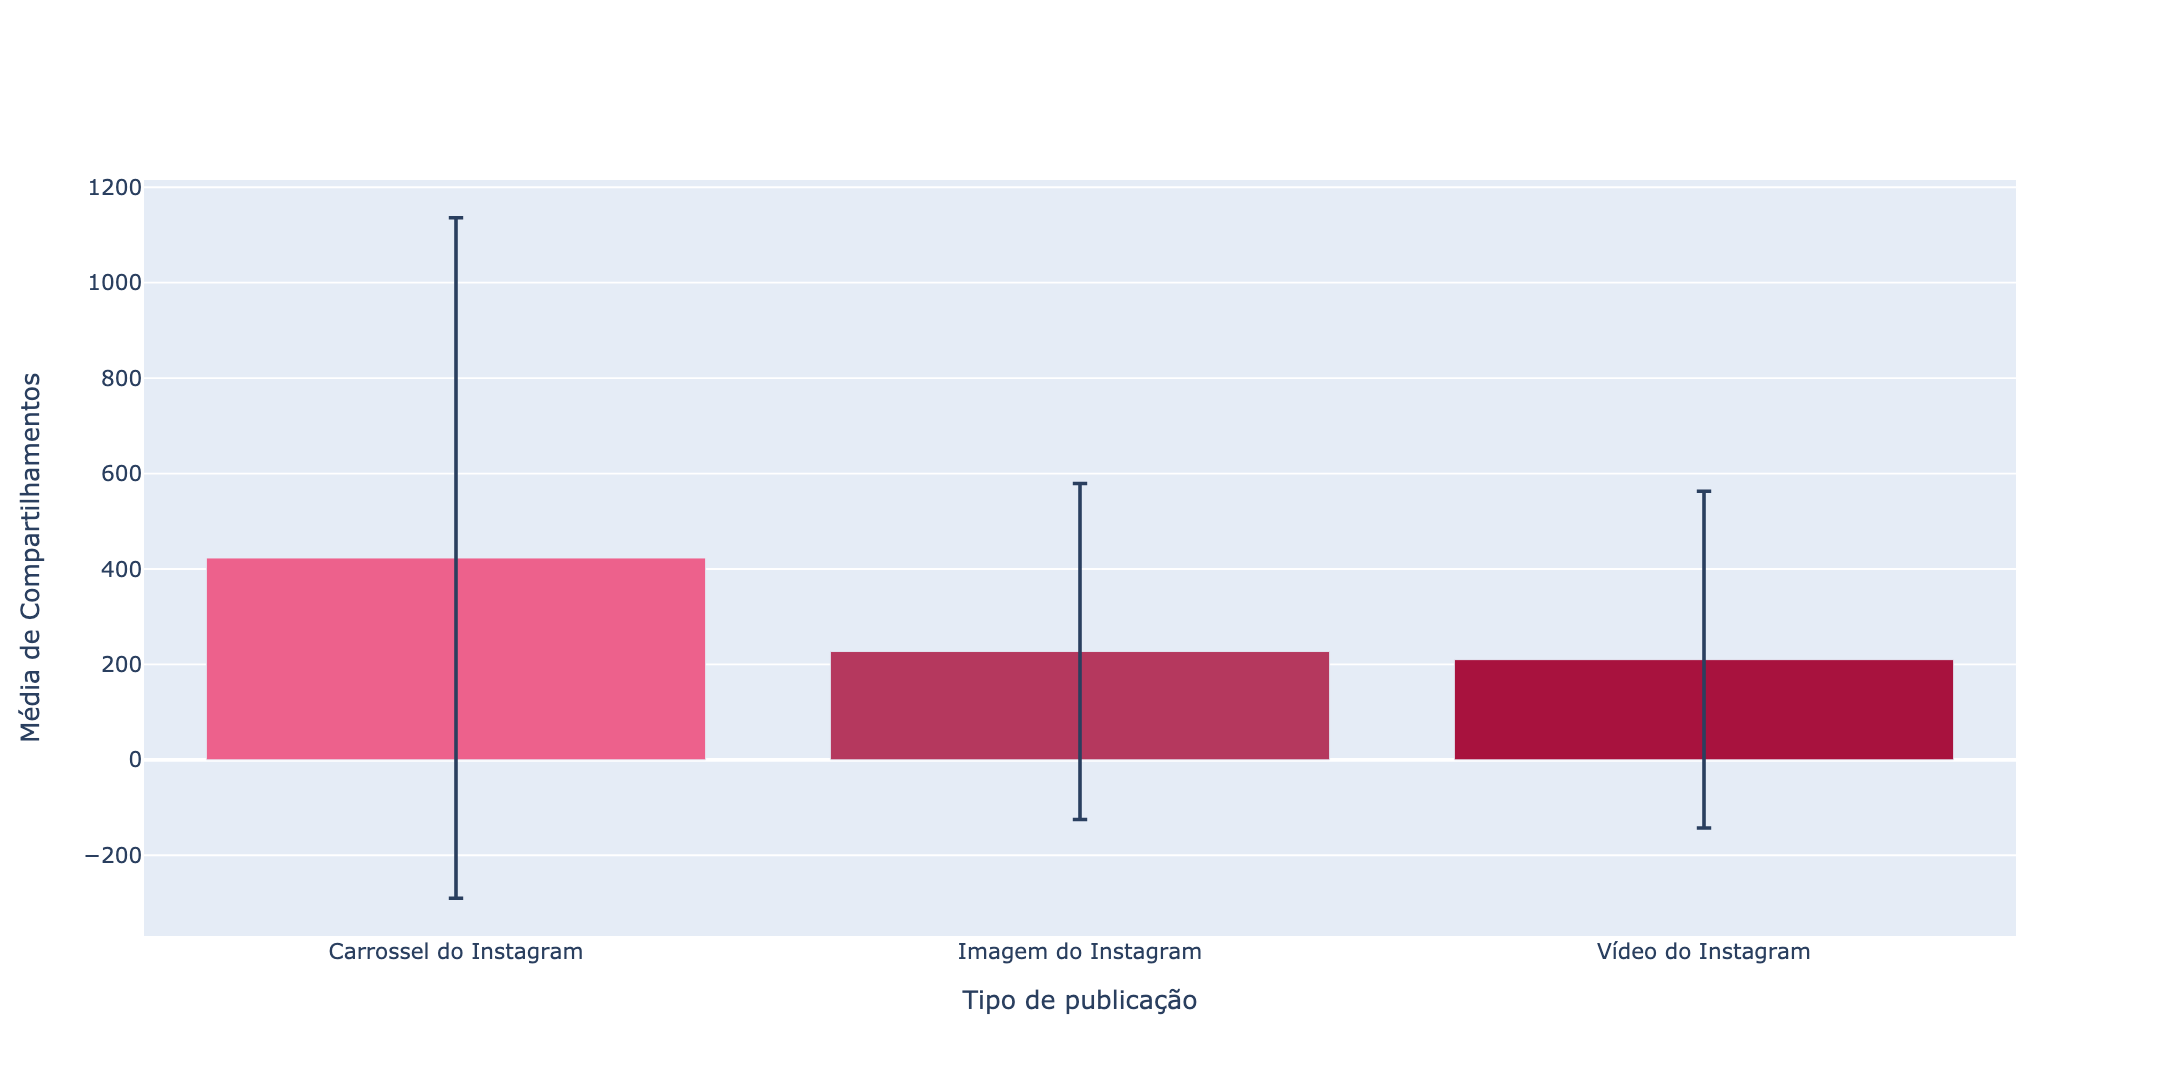

In [32]:
fig.show('png', scale=1.8)

# Exportando planilha com os 5 melhores e piores posts por métrica e por categoria de post 

## criando função para buscar os dados

In [33]:
def obter_dados(dataframe1, coluna_interesse1, extremo1, dataframe2, coluna_interesse2, extremo2, dataframe3, coluna_interesse3, extremo3, n=5):
    if extremo1 == 'maiores':
        df1 = dataframe1[['link_permanente', 'tipo_de_publicação', coluna_interesse1, 'data', 'horario']].nlargest(n, coluna_interesse1)
    elif extremo1 == 'menores':
        df1 = dataframe1[['link_permanente', 'tipo_de_publicação', coluna_interesse1, 'data', 'horario']].nsmallest(n, coluna_interesse1)
    else:
        raise ValueError("O argumento 'extremo1' deve ser 'maiores' ou 'menores'.")
    
    if extremo2 == 'maiores':
        df2 = dataframe2[['link_permanente', 'tipo_de_publicação', coluna_interesse2, 'data', 'horario']].nlargest(n, coluna_interesse2)
    elif extremo2 == 'menores':
        df2 = dataframe2[['link_permanente', 'tipo_de_publicação', coluna_interesse2, 'data', 'horario']].nsmallest(n, coluna_interesse2)
    else:
        raise ValueError("O argumento 'extremo2' deve ser 'maiores' ou 'menores'.")
    
    if extremo3 == 'maiores':
        df3 = dataframe3[['link_permanente', 'tipo_de_publicação', coluna_interesse3, 'data', 'horario']].nlargest(n, coluna_interesse3)
    elif extremo3 == 'menores':
        df3 = dataframe3[['link_permanente', 'tipo_de_publicação', coluna_interesse3, 'data', 'horario']].nsmallest(n, coluna_interesse3)
    else:
        raise ValueError("O argumento 'extremo3' deve ser 'maiores' ou 'menores'.")
    
    df_concatenado = pd.concat([df1, df2, df3], ignore_index=True)
    return df_concatenado

## Top 5 melhores/piores Alance por tipo de post 


In [34]:
df_melhor_alcance = obter_dados(df_carrossel,'alcance', 'maiores', df_post_unico, 'alcance', 'maiores', df_video, 'alcance', 'maiores')

df_melhor_alcance

,link_permanente,tipo_de_publicação,alcance,data,horario
0,https://www.instagram.com/p/Cm6lRXjs1Iv/,Carrossel do Instagram,87576,2023-01-02,06:01
1,https://www.instagram.com/p/CjgaSc4uSrE/,Carrossel do Instagram,57917,2022-10-09,13:10
2,https://www.instagram.com/p/Ci-5kKrueYj/,Carrossel do Instagram,56137,2022-09-26,13:09
3,https://www.instagram.com/p/CktDxvTuGrk/,Carrossel do Instagram,52409,2022-11-08,06:11
4,https://www.instagram.com/p/CpgINg2OdGT/,Carrossel do Instagram,52310,2023-03-07,13:03
5,https://www.instagram.com/p/Cg2m85fhTej/,Imagem do Instagram,56945,2022-08-04,14:08
6,https://www.instagram.com/p/CnXtrgTuc-r/,Imagem do Instagram,56367,2023-01-13,13:01
7,https://www.instagram.com/p/ChalKb9rj_i/,Imagem do Instagram,45750,2022-08-18,14:08
8,https://www.instagram.com/p/CafeTCHKGgJ/,Imagem do Instagram,42813,2022-02-27,11:02
9,https://www.instagram.com/p/CYPb0Rnt3IN/,Imagem do Instagram,38360,2022-01-02,12:01


In [35]:
df_pior_alcance = obter_dados(df_carrossel,'alcance', 'menores', df_post_unico, 'alcance', 'menores', df_video, 'alcance', 'menores')

df_pior_alcance

,link_permanente,tipo_de_publicação,alcance,data,horario
0,https://www.instagram.com/p/Cp5f-gfOhjw/,Carrossel do Instagram,2815,2023-03-17,10:03
1,https://www.instagram.com/p/CpFTmKWMIER/,Carrossel do Instagram,2967,2023-02-25,03:02
2,https://www.instagram.com/p/Co4ifO3Mura/,Carrossel do Instagram,3023,2023-02-20,04:02
3,https://www.instagram.com/p/CfaBimoKWts/,Carrossel do Instagram,3334,2022-06-29,15:06
4,https://www.instagram.com/p/Cp42d25O9a9/,Carrossel do Instagram,3471,2023-03-17,04:03
5,https://www.instagram.com/p/CgEq2nLtR0-/,Imagem do Instagram,3968,2022-07-16,05:07
6,https://www.instagram.com/p/CgIH7J3I355/,Imagem do Instagram,4127,2022-07-17,13:07
7,https://www.instagram.com/p/CgfaZJIrA0P/,Imagem do Instagram,4165,2022-07-26,14:07
8,https://www.instagram.com/p/Clj5ygpON3f/,Imagem do Instagram,4180,2022-11-29,14:11
9,https://www.instagram.com/p/Cn4YWV6Jm7t/,Imagem do Instagram,4408,2023-01-26,06:01


## Top 5 melhores/piores Impressões por tipo de post 

In [36]:
df_melhor_impressao = obter_dados(df_carrossel,'impressões', 'maiores', df_post_unico, 'impressões', 'maiores', df_video, 'impressões', 'maiores')

df_melhor_impressao

,link_permanente,tipo_de_publicação,impressões,data,horario
0,https://www.instagram.com/p/Cm6lRXjs1Iv/,Carrossel do Instagram,103140,2023-01-02,06:01
1,https://www.instagram.com/p/Ch0j3rFLUV8/,Carrossel do Instagram,97785,2022-08-28,16:08
2,https://www.instagram.com/p/CjgaSc4uSrE/,Carrossel do Instagram,72948,2022-10-09,13:10
3,https://www.instagram.com/p/CpgINg2OdGT/,Carrossel do Instagram,71217,2023-03-07,13:03
4,https://www.instagram.com/p/CePP7Vusy8q/,Carrossel do Instagram,68723,2022-05-31,14:05
5,https://www.instagram.com/p/Cg2m85fhTej/,Imagem do Instagram,63040,2022-08-04,14:08
6,https://www.instagram.com/p/CnXtrgTuc-r/,Imagem do Instagram,58152,2023-01-13,13:01
7,https://www.instagram.com/p/ChalKb9rj_i/,Imagem do Instagram,50745,2022-08-18,14:08
8,https://www.instagram.com/p/CafeTCHKGgJ/,Imagem do Instagram,45463,2022-02-27,11:02
9,https://www.instagram.com/p/CYPb0Rnt3IN/,Imagem do Instagram,41786,2022-01-02,12:01


In [37]:
df_pior_impressao = obter_dados(df_carrossel,'impressões', 'menores', df_post_unico, 'impressões', 'menores', df_video, 'impressões', 'menores')

df_pior_impressao

,link_permanente,tipo_de_publicação,impressões,data,horario
0,https://www.instagram.com/p/Cp5f-gfOhjw/,Carrossel do Instagram,3519,2023-03-17,10:03
1,https://www.instagram.com/p/CpFTmKWMIER/,Carrossel do Instagram,3807,2023-02-25,03:02
2,https://www.instagram.com/p/Co4ifO3Mura/,Carrossel do Instagram,3977,2023-02-20,04:02
3,https://www.instagram.com/p/Cp5yNPrOipH/,Carrossel do Instagram,4247,2023-03-17,13:03
4,https://www.instagram.com/p/CfaBimoKWts/,Carrossel do Instagram,4257,2022-06-29,15:06
5,https://www.instagram.com/p/Clj5ygpON3f/,Imagem do Instagram,4608,2022-11-29,14:11
6,https://www.instagram.com/p/CgEq2nLtR0-/,Imagem do Instagram,4646,2022-07-16,05:07
7,https://www.instagram.com/p/CgIH7J3I355/,Imagem do Instagram,4708,2022-07-17,13:07
8,https://www.instagram.com/p/Cn4YWV6Jm7t/,Imagem do Instagram,4820,2023-01-26,06:01
9,https://www.instagram.com/p/CgfaZJIrA0P/,Imagem do Instagram,5031,2022-07-26,14:07


## Top 5 melhores/piores Compartilhamentos por tipo de post 


In [38]:
df_melhor_compart = obter_dados(df_carrossel,'compartilhamentos', 'maiores', df_post_unico, 'compartilhamentos', 'maiores',
                                df_video, 'compartilhamentos', 'maiores')

df_melhor_compart

,link_permanente,tipo_de_publicação,compartilhamentos,data,horario
0,https://www.instagram.com/p/Ch0j3rFLUV8/,Carrossel do Instagram,5214,2022-08-28,16:08
1,https://www.instagram.com/p/CgrZhiCACDL/,Carrossel do Instagram,4305,2022-07-31,06:07
2,https://www.instagram.com/p/CfCoG1kvcpH/,Carrossel do Instagram,4007,2022-06-20,13:06
3,https://www.instagram.com/p/ChNB8otB5iE/,Carrossel do Instagram,3529,2022-08-13,07:08
4,https://www.instagram.com/p/CeJUcmWPf9L/,Carrossel do Instagram,3342,2022-05-29,07:05
5,https://www.instagram.com/p/Cg2m85fhTej/,Imagem do Instagram,1954,2022-08-04,14:08
6,https://www.instagram.com/p/ChalKb9rj_i/,Imagem do Instagram,1753,2022-08-18,14:08
7,https://www.instagram.com/p/CdyG7vphuC5/,Imagem do Instagram,1669,2022-05-20,07:05
8,https://www.instagram.com/p/CnXtrgTuc-r/,Imagem do Instagram,1199,2023-01-13,13:01
9,https://www.instagram.com/p/CZAYqUqMKvw/,Imagem do Instagram,844,2022-01-21,12:01


In [39]:
df_pior_compart = obter_dados(df_carrossel,'compartilhamentos', 'menores', df_post_unico, 'compartilhamentos', 'menores',
                           df_video, 'compartilhamentos', 'menores')


df_pior_compart

,link_permanente,tipo_de_publicação,compartilhamentos,data,horario
0,https://www.instagram.com/p/Cewm11puQaP/,Carrossel do Instagram,0,2022-06-13,13:06
1,https://www.instagram.com/p/Ce8kb6ftlxR/,Carrossel do Instagram,0,2022-06-18,05:06
2,https://www.instagram.com/p/CeMsM7FLXUF/,Carrossel do Instagram,1,2022-05-30,15:05
3,https://www.instagram.com/p/Ce9f_dlIIt6/,Carrossel do Instagram,1,2022-06-18,14:06
4,https://www.instagram.com/p/Co4ifO3Mura/,Carrossel do Instagram,1,2023-02-20,04:02
5,https://www.instagram.com/p/CgEq2nLtR0-/,Imagem do Instagram,0,2022-07-16,05:07
6,https://www.instagram.com/p/Clj5ygpON3f/,Imagem do Instagram,0,2022-11-29,14:11
7,https://www.instagram.com/p/Cb8bYtQOANF/,Imagem do Instagram,2,2022-04-04,14:04
8,https://www.instagram.com/p/CgfaZJIrA0P/,Imagem do Instagram,2,2022-07-26,14:07
9,https://www.instagram.com/p/CeWRrkkONeu/,Imagem do Instagram,4,2022-06-03,08:06


## top 5 melhores/piores Curtidas por tipo de post


In [40]:
df_melhor_curtida = obter_dados(df_carrossel,'curtidas', 'maiores', df_post_unico, 'curtidas', 'maiores', df_video, 'curtidas', 'maiores')

df_melhor_curtida

,link_permanente,tipo_de_publicação,curtidas,data,horario
0,https://www.instagram.com/p/CgrZhiCACDL/,Carrossel do Instagram,7376,2022-07-31,06:07
1,https://www.instagram.com/p/CjgaSc4uSrE/,Carrossel do Instagram,6240,2022-10-09,13:10
2,https://www.instagram.com/p/CfSGVsRI0XN/,Carrossel do Instagram,5958,2022-06-26,14:06
3,https://www.instagram.com/p/CdlPuY4Nai_/,Carrossel do Instagram,5727,2022-05-15,07:05
4,https://www.instagram.com/p/Cdy6ErjByn3/,Carrossel do Instagram,5478,2022-05-20,14:05
5,https://www.instagram.com/p/Cg2m85fhTej/,Imagem do Instagram,4788,2022-08-04,14:08
6,https://www.instagram.com/p/CnhorTQO_7u/,Imagem do Instagram,4044,2023-01-17,10:01
7,https://www.instagram.com/p/CnXtrgTuc-r/,Imagem do Instagram,4037,2023-01-13,13:01
8,https://www.instagram.com/p/CZFWOcGsXFu/,Imagem do Instagram,3407,2022-01-23,11:01
9,https://www.instagram.com/p/CdyG7vphuC5/,Imagem do Instagram,3088,2022-05-20,07:05


In [41]:
df_pior_curtida = obter_dados(df_carrossel,'curtidas', 'menores', df_post_unico, 'curtidas', 'menores', df_video, 'curtidas', 'menores')


df_pior_curtida

,link_permanente,tipo_de_publicação,curtidas,data,horario
0,https://www.instagram.com/p/CpFTmKWMIER/,Carrossel do Instagram,27,2023-02-25,03:02
1,https://www.instagram.com/p/CmUFHH4uraw/,Carrossel do Instagram,34,2022-12-18,07:12
2,https://www.instagram.com/p/Co4ifO3Mura/,Carrossel do Instagram,34,2023-02-20,04:02
3,https://www.instagram.com/p/CfaBimoKWts/,Carrossel do Instagram,40,2022-06-29,15:06
4,https://www.instagram.com/p/Cfe9nwEoGvC/,Carrossel do Instagram,46,2022-07-01,13:07
5,https://www.instagram.com/p/CgEq2nLtR0-/,Imagem do Instagram,34,2022-07-16,05:07
6,https://www.instagram.com/p/Clj5ygpON3f/,Imagem do Instagram,34,2022-11-29,14:11
7,https://www.instagram.com/p/CgfaZJIrA0P/,Imagem do Instagram,47,2022-07-26,14:07
8,https://www.instagram.com/p/CgIH7J3I355/,Imagem do Instagram,59,2022-07-17,13:07
9,https://www.instagram.com/p/Cb8bYtQOANF/,Imagem do Instagram,63,2022-04-04,14:04


## Top 5 melhores/piores Comentarios por tipo de post

In [42]:
df_melhor_coment = obter_dados(df_carrossel,'comentários', 'maiores', df_post_unico, 'comentários', 'maiores', df_video, 'comentários', 'maiores')

df_melhor_coment

,link_permanente,tipo_de_publicação,comentários,data,horario
0,https://www.instagram.com/p/CktDxvTuGrk/,Carrossel do Instagram,398,2022-11-08,06:11
1,https://www.instagram.com/p/CeBSDv7ppz7/,Carrossel do Instagram,384,2022-05-26,04:05
2,https://www.instagram.com/p/CfCoG1kvcpH/,Carrossel do Instagram,192,2022-06-20,13:06
3,https://www.instagram.com/p/CmonI7Gs4E-/,Carrossel do Instagram,140,2022-12-26,06:12
4,https://www.instagram.com/p/Cp0rJACIJID/,Carrossel do Instagram,138,2023-03-15,13:03
5,https://www.instagram.com/p/Cp5K9k7uCEd/,Imagem do Instagram,738,2023-03-17,07:03
6,https://www.instagram.com/p/Ca0XJesuYNv/,Imagem do Instagram,725,2022-03-07,13:03
7,https://www.instagram.com/p/CdyG7vphuC5/,Imagem do Instagram,176,2022-05-20,07:05
8,https://www.instagram.com/p/CYUkhXqIaug/,Imagem do Instagram,155,2022-01-04,12:01
9,https://www.instagram.com/p/CnhorTQO_7u/,Imagem do Instagram,149,2023-01-17,10:01


In [43]:
df_pior_coment = obter_dados(df_carrossel,'comentários', 'menores', df_post_unico, 'comentários', 'menores', df_video, 'comentários', 'menores')

df_pior_coment

,link_permanente,tipo_de_publicação,comentários,data,horario
0,https://www.instagram.com/p/Ca0L8Pps-aP/,Carrossel do Instagram,0,2022-03-07,12:03
1,https://www.instagram.com/p/CcxtvQdtzvr/,Carrossel do Instagram,0,2022-04-25,07:04
2,https://www.instagram.com/p/CeZaXUVr9YB/,Carrossel do Instagram,0,2022-06-04,13:06
3,https://www.instagram.com/p/Ce1CFptpavp/,Carrossel do Instagram,0,2022-06-15,07:06
4,https://www.instagram.com/p/Ce8v-Myjb62/,Carrossel do Instagram,0,2022-06-18,07:06
5,https://www.instagram.com/p/CctTcgUIs_U/,Imagem do Instagram,0,2022-04-23,14:04
6,https://www.instagram.com/p/CdBOkWIr3tL/,Imagem do Instagram,0,2022-05-01,07:05
7,https://www.instagram.com/p/CfWh8B5OAPt/,Imagem do Instagram,0,2022-06-28,07:06
8,https://www.instagram.com/p/CgCyPvphXRq/,Imagem do Instagram,0,2022-07-15,11:07
9,https://www.instagram.com/p/CgEq2nLtR0-/,Imagem do Instagram,0,2022-07-16,05:07


## Top 5 melhores/piores Salvamentos por tipo de post 


In [44]:
df_melhor_salvamento = obter_dados(df_carrossel,'salvamentos', 'maiores', df_post_unico, 'salvamentos', 'maiores', df_video, 'salvamentos', 'maiores')

df_melhor_salvamento

,link_permanente,tipo_de_publicação,salvamentos,data,horario
0,https://www.instagram.com/p/CePP7Vusy8q/,Carrossel do Instagram,3316,2022-05-31,14:05
1,https://www.instagram.com/p/Cih0zqRvDlN/,Carrossel do Instagram,2501,2022-09-15,06:09
2,https://www.instagram.com/p/Cm6lRXjs1Iv/,Carrossel do Instagram,2087,2023-01-02,06:01
3,https://www.instagram.com/p/Cdy6ErjByn3/,Carrossel do Instagram,1657,2022-05-20,14:05
4,https://www.instagram.com/p/CmM4KxjLM4u/,Carrossel do Instagram,1212,2022-12-15,12:12
5,https://www.instagram.com/p/Cg2m85fhTej/,Imagem do Instagram,1034,2022-08-04,14:08
6,https://www.instagram.com/p/ChalKb9rj_i/,Imagem do Instagram,604,2022-08-18,14:08
7,https://www.instagram.com/p/CZAYqUqMKvw/,Imagem do Instagram,459,2022-01-21,12:01
8,https://www.instagram.com/p/CoM-tZBLcMM/,Imagem do Instagram,290,2023-02-03,06:02
9,https://www.instagram.com/p/CqYq1PNvPUR/,Imagem do Instagram,276,2023-03-29,13:03


In [45]:
df_pior_salvamento = obter_dados(df_carrossel,'salvamentos', 'menores', df_post_unico, 'salvamentos', 'menores', df_video, 'salvamentos', 'menores')

df_pior_salvamento

,link_permanente,tipo_de_publicação,salvamentos,data,horario
0,https://www.instagram.com/p/Cp42d25O9a9/,Carrossel do Instagram,0,2023-03-17,04:03
1,https://www.instagram.com/p/CfPkGpWvH_h/,Carrossel do Instagram,1,2022-06-25,14:06
2,https://www.instagram.com/p/Co4ifO3Mura/,Carrossel do Instagram,1,2023-02-20,04:02
3,https://www.instagram.com/p/CpFTmKWMIER/,Carrossel do Instagram,1,2023-02-25,03:02
4,https://www.instagram.com/p/Cox_pB5NQRm/,Carrossel do Instagram,2,2023-02-17,15:02
5,https://www.instagram.com/p/CgEq2nLtR0-/,Imagem do Instagram,0,2022-07-16,05:07
6,https://www.instagram.com/p/Cba88WQOkvR/,Imagem do Instagram,2,2022-03-22,14:03
7,https://www.instagram.com/p/CeWRrkkONeu/,Imagem do Instagram,3,2022-06-03,08:06
8,https://www.instagram.com/p/CiLZ_FYOKcY/,Imagem do Instagram,4,2022-09-06,13:09
9,https://www.instagram.com/p/CiLaOnrOSyJ/,Imagem do Instagram,4,2022-09-06,13:09


## Top 5 melhores/piores Seguimentos por tipo de post

In [46]:
df_melhor_seguimento = obter_dados(df_carrossel,'seguimentos', 'maiores', df_post_unico, 'seguimentos', 'maiores', df_video, 'seguimentos', 'maiores')

df_melhor_seguimento

,link_permanente,tipo_de_publicação,seguimentos,data,horario
0,https://www.instagram.com/p/Cm6lRXjs1Iv/,Carrossel do Instagram,688,2023-01-02,06:01
1,https://www.instagram.com/p/Cdy6ErjByn3/,Carrossel do Instagram,445,2022-05-20,14:05
2,https://www.instagram.com/p/CjgaSc4uSrE/,Carrossel do Instagram,379,2022-10-09,13:10
3,https://www.instagram.com/p/Cm6l2ALsME3/,Carrossel do Instagram,276,2023-01-02,06:01
4,https://www.instagram.com/p/CePP7Vusy8q/,Carrossel do Instagram,228,2022-05-31,14:05
5,https://www.instagram.com/p/Cg2m85fhTej/,Imagem do Instagram,118,2022-08-04,14:08
6,https://www.instagram.com/p/CfruCBAOdHx/,Imagem do Instagram,58,2022-07-06,12:07
7,https://www.instagram.com/p/CaAwmBRvXSc/,Imagem do Instagram,57,2022-02-15,12:02
8,https://www.instagram.com/p/CZMju-lM-Vl/,Imagem do Instagram,42,2022-01-26,06:01
9,https://www.instagram.com/p/Ca0XJesuYNv/,Imagem do Instagram,40,2022-03-07,13:03


In [47]:
df_pior_seguimento = obter_dados(df_carrossel,'seguimentos', 'menores', df_post_unico, 'seguimentos', 'menores', df_video, 'seguimentos', 'menores')

df_pior_seguimento

,link_permanente,tipo_de_publicação,seguimentos,data,horario
0,https://www.instagram.com/p/Cc6JwgArmQM/,Carrossel do Instagram,0,2022-04-28,13:04
1,https://www.instagram.com/p/CeEvBtWhaD0/,Carrossel do Instagram,0,2022-05-27,12:05
2,https://www.instagram.com/p/CeMsM7FLXUF/,Carrossel do Instagram,0,2022-05-30,15:05
3,https://www.instagram.com/p/CeYw6-htijA/,Carrossel do Instagram,0,2022-06-04,07:06
4,https://www.instagram.com/p/Cewm11puQaP/,Carrossel do Instagram,0,2022-06-13,13:06
5,https://www.instagram.com/p/CctTcgUIs_U/,Imagem do Instagram,0,2022-04-23,14:04
6,https://www.instagram.com/p/Cdn8zMFuGdO/,Imagem do Instagram,0,2022-05-16,08:05
7,https://www.instagram.com/p/Cd8ZfHNKISw/,Imagem do Instagram,0,2022-05-24,07:05
8,https://www.instagram.com/p/CeOkJkBNQAr/,Imagem do Instagram,0,2022-05-31,08:05
9,https://www.instagram.com/p/CeWRrkkONeu/,Imagem do Instagram,0,2022-06-03,08:06
